# Walmart Weekly Sales Analysis

### BMT5101 Group Project

**Group:** Crazy Tuesday  
**Members:** Bi Heng · Liu Jingwei · Xie Zhenyu · Yang Wenxi · Liu Faran

## Study Overview

This study examines weekly sales patterns in a panel of 45 anonymous Walmart stores between 5 February 2010 and 26 October 2012. The group-supplied file, `Walmart_sales_analysis.csv`, contains 6,435 store-week observations. The analysis combines data validation with visual comparisons of sales over time, differences across stores and holiday-labelled weeks.

Three substantive questions guide the analysis:

1. **Time patterns:** Are recurring seasonal peaks more pronounced than year-to-year changes in average weekly sales?
2. **Store performance:** How large are the differences in typical sales, and are the highest-selling stores also the most stable in relative terms?
3. **Holiday labels:** How do holiday-labelled weeks compare with other weeks, and does the indicator capture the largest seasonal sales peaks?

### Why This Dataset Is Suitable

The dataset links weekly dates, repeated store identifiers, reported sales and a binary holiday flag in one panel. Dates support the examination of time patterns; repeated observations on the same stores support comparisons of sales levels and relative variability; and the holiday flag supports comparisons of selected labelled weeks with other weeks. Module A verifies that store-date coverage is complete before these properties are used in the analysis.

The combination is also analytically informative: an aggregate sales pattern can be compared with store-level variation, while labelled holiday dates can be checked against the actual peak weeks. This allows the three questions to be connected rather than treated as separate descriptive exercises.

Module A establishes the data foundation for these questions. The subsequent modules examine complementary dimensions of the same historical sample:

| Module | Analytical focus | Main evidence |
|---|---|---|
| A | Data quality and the meaning of an overall average | Coverage checks, descriptive statistics and the pooled sales distribution |
| B | Time patterns and seasonality | Weekly averages, a four-week moving average, monthly comparisons and common-period yearly averages |
| C | Store sales levels and relative stability | Store rankings, mean–CV comparisons and selected sales distributions |
| D | Holiday-labelled weeks and indicator coverage | Pooled and within-store comparisons, inferred event types and unflagged December peaks |

Sales retain the file's reported values; the currency has not been independently verified. Figures expressed in millions are rescaled for presentation only. All findings are descriptive and apply to the observed stores and dates.

## Module A: Data Quality and Descriptive Overview

**Research question:** Is the store-week panel complete, and how well does mean sales represent a typical observation?

The source data are preserved before cleaning. Validation assesses whether subsequent comparisons use complete, unique and consistently interpreted store-week records. Extreme observations are investigated without being automatically removed.


### A.1 Data Source and Initial Setup

The supplied analysis file is associated with the Kaggle Walmart dataset listed in Reference [1]. Its exact download history, file lineage and original measurement units remain unverified. The source association is documented without assuming that it independently verifies every value in the supplied CSV.

Shared libraries and the original file are loaded once. `raw_df` preserves the source representation, while working copies support cleaning and the separate analytical modules. This arrangement maintains traceability between the original data and reported results.


In [3]:
# Load shared libraries and preserve the supplied CSV as raw_df.
# All later modules reuse this source or the cleaned data prepared in Module A.
import pandas as pd

import matplotlib.pyplot as plt

from pathlib import Path

from IPython.display import display
import numpy as np
from matplotlib.ticker import PercentFormatter
import json

# Source association: Kaggle Walmart Dataset, uploaded by M. Yasser H.
# https://www.kaggle.com/datasets/yasserh/walmart-dataset
# The source page was reviewed on 28 October 2026, but its data-card text was unavailable.
# The original download history, exact file lineage and currency remain unverified.
# Each source row represents one anonymous store in one reported week.
file_name = 'Walmart_sales_analysis.csv'

# In Colab, upload the original CSV if it is absent from the working folder.
# Outside Colab, retain the agreed filename beside the notebook.
if not Path(file_name).is_file():
    try:

        from google.colab import files
        files.upload()
    except ImportError:

        pass

if not Path(file_name).is_file():
    raise FileNotFoundError(
        'Upload Walmart_sales_analysis.csv to the current working folder, '
        'keep its original filename, and run this cell again.'
    )

# Keep raw values unchanged; transformations are applied to a separate working copy.
raw_df = pd.read_csv(file_name)


### A.2 Original Data Structure

Initial inspection records the source dimensions, column names and data types. The file contains 6,435 rows and eight source fields. Sales values are initially represented as comma-separated text, dates are stored as text, and the CPI column contains surrounding spaces in its name.

These representation issues require standardisation before numerical calculations and date-based grouping. They do not, by themselves, justify changing sales amounts or discarding observations.


In [5]:
# Create a separate working copy called df
# This leaves the original values and column names in raw_df unchanged
df = raw_df.copy()

# Show the number of rows and columns before making any changes
print('Original shape:', raw_df.shape)

# Show the first five rows to understand how the data is organized
display(raw_df.head())

# Display the original column names using repr so spaces remain visible
# For example, the supplied CPI column has spaces before and after its name
print('Original column names:')
print([repr(column) for column in raw_df.columns])

# Display the original data types
# Weekly_Sales and Date are initially read as text
display(raw_df.dtypes.rename('Original data type').to_frame())

Original shape: (6435, 8)


,Store_Number,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,2/5/2010,"1,643,691",0,42.31,2.572,211,8.106
1,1,2/12/2010,"1,641,957",1,38.51,2.548,211,8.106
2,1,2/19/2010,"1,611,968",0,39.93,2.514,211,8.106
3,1,2/26/2010,"1,409,728",0,46.63,2.561,211,8.106
4,1,3/5/2010,"1,554,807",0,46.50,2.625,211,8.106


Original column names:
["'Store_Number'", "'Date'", "'Weekly_Sales'", "'Holiday_Flag'", "'Temperature'", "'Fuel_Price'", "' CPI '", "'Unemployment'"]


,Original data type
Store_Number,int64
Date,object
Weekly_Sales,object
Holiday_Flag,int64
Temperature,float64
Fuel_Price,float64
CPI,int64
Unemployment,float64


### A.3 Variable Definitions and Measurement Scope

Each row represents reported sales for one anonymous store in one week. The variable dictionary distinguishes store identifiers and the holiday category from measured numeric fields.

- **Store_Number:** an identifier; its numeric ordering does not describe store size, location or performance.
- **Date and Weekly_Sales:** identify the reported week and its associated store sales value.
- **Holiday_Flag:** the provider's binary label for selected weeks, rather than a complete classification of seasonal shopping activity.
- **Temperature, Fuel_Price, CPI and Unemployment:** contextual fields described in the dataset but not used to identify causal effects in this study.

The source does not independently establish the currency, temperature scale or fuel-price units. Sales and CPI are integer-valued in the supplied file; any absent original precision cannot be reconstructed through cleaning.


In [7]:
# Create a field dictionary so the group uses the same meaning for each variable
# Store_Number is an identifier, rather than a continuous numeric measurement
# Holiday_Flag is a provider-defined label, rather than a complete list of shopping peaks
data_dictionary = pd.DataFrame({
    'Variable': ['Store_Number', 'Date', 'Weekly_Sales', 'Holiday_Flag',
                 'Temperature', 'Fuel_Price', 'CPI', 'Unemployment'],
    'Meaning': ['Anonymous store identifier', 'Date identifying the reported sales week',
                'Reported sales for one store in one week',
                'Special holiday-labelled week: 1 = yes, 0 = no',
                'Reported temperature associated with the store and week',
                'Reported regional fuel price', 'Reported consumer price index',
                'Reported unemployment-rate value'],
    'Type after cleaning': ['Categorical identifier (string)', 'Datetime', 'Numeric',
                            'Binary category', 'Numeric', 'Numeric', 'Numeric index', 'Numeric rate']
})
display(data_dictionary)

# The CSV does not identify the currency of Weekly_Sales
# Graphs will use reported sales value instead of assuming the values are USD
# Temperature and fuel-price units are also left unverified, so no unit conversions are made
# Sales and CPI are integer-valued in this file; missing original precision cannot be recovered

,Variable,Meaning,Type after cleaning
0,Store_Number,Anonymous store identifier,Categorical identifier (string)
1,Date,Date identifying the reported sales week,Datetime
2,Weekly_Sales,Reported sales for one store in one week,Numeric
3,Holiday_Flag,"Special holiday-labelled week: 1 = yes, 0 = no",Binary category
4,Temperature,Reported temperature associated with the store...,Numeric
5,Fuel_Price,Reported regional fuel price,Numeric
6,CPI,Reported consumer price index,Numeric index
7,Unemployment,Reported unemployment-rate value,Numeric rate


### A.4 Cleaning and Conversion Checks

Column names are stripped of surrounding spaces, comma-separated sales are converted to numeric values, and dates are parsed explicitly using the month/day/year convention. This interprets `2/5/2010` as 5 February 2010. Store identifiers are retained as text in the shared cleaned dataset.

Missing-value counts are compared before and after conversion. The assertions below ensure that a failed conversion cannot silently remove a valid source value from later calculations. The original sales scale is retained throughout the numerical analysis.


In [9]:
# Remove extra spaces before or after column names
# This changes ' CPI ' into 'CPI' and makes column references consistent
df.columns = df.columns.str.strip()

# Display the original and cleaned column names together
display(pd.DataFrame({
    'Original name': [repr(column) for column in raw_df.columns],
    'Cleaned name': df.columns
}))

# Save the original missing-value counts before converting sales and dates
# Comparing before and after reveals values that fail to convert
sales_missing_before = df['Weekly_Sales'].isna().sum()
date_missing_before = df['Date'].isna().sum()

# Remove thousands commas and convert Weekly_Sales into numeric values
# errors='coerce' turns an invalid value into NaN so conversion failures remain visible
df['Weekly_Sales'] = pd.to_numeric(
    df['Weekly_Sales'].astype(str).str.replace(',', '', regex=False), errors='coerce'
).astype(float)

# Convert Date using the explicit month/day/year format
# This interprets 2/5/2010 as 5 February 2010, rather than 2 May 2010
# An invalid date becomes NaT and will be checked below
df['Date'] = pd.to_datetime(df['Date'], format='%m/%d/%Y', errors='coerce')

# Convert the store identifier into text to avoid treating it as a measured variable
# This keeps the column name Store_Number unchanged for the other modules
df['Store_Number'] = df['Store_Number'].astype('string')

# Calculate how many missing values were introduced by the conversions
sales_conversion_failures = df['Weekly_Sales'].isna().sum() - sales_missing_before
date_conversion_failures = df['Date'].isna().sum() - date_missing_before

print('New missing sales values:', sales_conversion_failures)
print('New missing dates:', date_conversion_failures)

# Stop if either conversion loses a non-missing source value
assert sales_conversion_failures == 0, 'Review sales values that failed to convert.'
assert date_conversion_failures == 0, 'Review dates that failed to convert.'

# Show the cleaned data and data types to verify the changes
display(df.head())
display(df.dtypes.rename('Cleaned data type').to_frame())

,Original name,Cleaned name
0,'Store_Number',Store_Number
1,'Date',Date
2,'Weekly_Sales',Weekly_Sales
3,'Holiday_Flag',Holiday_Flag
4,'Temperature',Temperature
5,'Fuel_Price',Fuel_Price
6,' CPI ',CPI
7,'Unemployment',Unemployment


New missing sales values: 0
New missing dates: 0


,Store_Number,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,2010-02-05,1643691.0,0,42.31,2.572,211,8.106
1,1,2010-02-12,1641957.0,1,38.51,2.548,211,8.106
2,1,2010-02-19,1611968.0,0,39.93,2.514,211,8.106
3,1,2010-02-26,1409728.0,0,46.63,2.561,211,8.106
4,1,2010-03-05,1554807.0,0,46.50,2.625,211,8.106


,Cleaned data type
Store_Number,string[python]
Date,datetime64[ns]
Weekly_Sales,float64
Holiday_Flag,int64
Temperature,float64
Fuel_Price,float64
CPI,int64
Unemployment,float64


### A.5 Missing Values, Duplicate Records and Holiday Flags

The validation distinguishes complete duplicate rows from repeated store-date keys. A repeated key would violate the intended unit of observation and could give a store-week excessive weight in averages or totals.

**Validation results:** no missing source-field values or duplicate store-date combinations are identified, and the holiday flag contains only the expected values of 0 and 1. Consequently, no deletion or imputation is required. These checks establish consistency within the supplied file rather than independent accuracy of the original data collection.


In [11]:
# Count missing values in every cleaned source field
missing_values = df.isna().sum()
print('Missing values by variable:')
display(missing_values.rename('Missing values').to_frame())

# Check repeated store-date combinations because each store should appear once per week
# A duplicate composite key could cause sales to be counted twice
duplicate_store_dates = df.duplicated(['Store_Number', 'Date']).sum()
print('Duplicate store-date combinations:', duplicate_store_dates)

# Also report completely duplicated rows
duplicate_rows = df.duplicated().sum()
print('Completely duplicated rows:', duplicate_rows)

# Check that the holiday flag contains only the original binary values 0 and 1
print('Holiday flag values:', sorted(df['Holiday_Flag'].unique()))

# Stop if these checks fail so later analysis does not silently use invalid data
assert missing_values.sum() == 0, 'Review missing source-field values.'
assert duplicate_store_dates == 0, 'Review duplicated store-date combinations.'
assert df['Holiday_Flag'].isin([0, 1]).all(), 'Review invalid holiday flags.'

# No rows are dropped or filled in because the supplied data passes these checks
# These checks establish completeness and uniqueness, not original source accuracy

Missing values by variable:


,Missing values
Store_Number,0
Date,0
Weekly_Sales,0
Holiday_Flag,0
Temperature,0
Fuel_Price,0
CPI,0
Unemployment,0


Duplicate store-date combinations: 0
Completely duplicated rows: 0
Holiday flag values: [0, 1]


### A.6 Observation Period and Panel Coverage

Coverage is assessed from both the store and date perspectives. Every store must appear on the complete expected sequence of weekly dates, and every date must contain all 45 stores. The checks verify the exact date sequence as well as record counts.

The sample runs from 5 February 2010 to 26 October 2012 and contains 143 weekly dates. A complete panel supports comparisons across stores without unequal observation periods driving the rankings. Calendar-year coverage is nevertheless incomplete at the beginning and end of the sample.


In [13]:
# Show the actual observation period and number of stores and weekly dates
print('First date:', df['Date'].min().strftime('%Y-%m-%d'))
print('Last date:', df['Date'].max().strftime('%Y-%m-%d'))
print('Number of stores:', df['Store_Number'].nunique())
print('Number of weekly dates:', df['Date'].nunique())
print('Number of observations:', len(df))

# Count rows and unique weeks for every store
# Store identifiers are sorted numerically for display only
store_coverage = df.groupby('Store_Number').agg(
    Observations=('Date', 'size'), Unique_weeks=('Date', 'nunique')
)
store_coverage = store_coverage.loc[sorted(store_coverage.index, key=int)]
display(store_coverage)

# Count unique stores and rows on every date
weekly_coverage = df.groupby('Date').agg(
    Stores=('Store_Number', 'nunique'), Observations=('Store_Number', 'size')
)

# Display the coverage frequency across all dates
# The expected result is one combination: 45 stores and 45 rows, repeated for 143 weeks
display(weekly_coverage.value_counts().rename('Number of weeks').reset_index())

# Generate the complete weekly date sequence expected by the guide
# Equality checks verify the exact dates, rather than only the number of weeks
expected_dates = pd.date_range('2010-02-05', '2012-10-26', freq='7D')
actual_dates = pd.DatetimeIndex(df['Date'].unique()).sort_values()

# Check the panel structure and confirm that the original row count is preserved
assert df.shape == (6435, 8), 'The supplied file differs from the expected source shape.'
assert set(df['Store_Number']) == {str(i) for i in range(1, 46)}, 'Review store IDs.'
assert actual_dates.equals(expected_dates), 'Review the expected weekly date sequence.'
assert store_coverage['Observations'].eq(143).all(), 'Review rows per store.'
assert store_coverage['Unique_weeks'].eq(143).all(), 'Review weekly coverage per store.'
assert weekly_coverage['Stores'].eq(45).all(), 'Review stores per week.'
assert weekly_coverage['Observations'].eq(45).all(), 'Review rows per week.'

# Check that all stores have the same holiday label on any given date
assert df.groupby('Date')['Holiday_Flag'].nunique().eq(1).all(), 'Review inconsistent holiday labels.'

print('Coverage checks passed: 45 stores × 143 weeks = 6,435 unique store-week records.')

# A complete panel supports comparisons across these stores and weeks
# It does not mean that these 45 stores represent all Walmart stores

First date: 2010-02-05
Last date: 2012-10-26
Number of stores: 45
Number of weekly dates: 143
Number of observations: 6435


,Observations,Unique_weeks
Store_Number,,
1,143,143
2,143,143
3,143,143
4,143,143
5,143,143
6,143,143
7,143,143
8,143,143
9,143,143


,Stores,Observations,Number of weeks
0,45,45,143


Coverage checks passed: 45 stores × 143 weeks = 6,435 unique store-week records.


### A.7 Descriptive Statistics and Holiday Frequencies

Descriptive statistics are calculated for measured numeric fields. Store identifiers are excluded because their values are labels, while `Holiday_Flag` is reported separately as a category. The numeric summary uses pandas' sample standard deviation (`ddof=1`).

The holiday counts have two distinct interpretations:

- **450 holiday-labelled store-week observations** represent 10 distinct dates, each covering 45 stores.
- **5,985 other store-week observations** represent 133 distinct dates, each covering the same stores.

The groups differ substantially in size. Moreover, observations share stores and calendar dates, so the row counts must not be interpreted as counts of independent holiday events.


In [15]:
# Select the measured numeric variables for descriptive statistics
# Exclude Store_Number because its numeric-looking labels have no quantitative meaning
# Report Holiday_Flag separately as a category
numeric_columns = ['Weekly_Sales', 'Temperature', 'Fuel_Price', 'CPI', 'Unemployment']

# Calculate count, mean, sample standard deviation, minimum, quartiles, median, and maximum
# pandas uses the sample standard deviation by default
summary_statistics = df[numeric_columns].describe().T
summary_statistics = summary_statistics[
    ['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']
].rename(columns={'50%': 'median'})
display(summary_statistics.round(2))

# Count holiday-labelled and non-holiday-labelled observations
# Divide each count by the total number of rows to calculate percentages
holiday_counts = df['Holiday_Flag'].value_counts().reindex([0, 1], fill_value=0)
holiday_summary = pd.DataFrame({
    'Label': ['Non-holiday-labelled', 'Holiday-labelled'],
    'Count': holiday_counts,
    'Percent': holiday_counts / len(df) * 100,
    'Unique_weeks': df.groupby('Holiday_Flag')['Date'].nunique().reindex([0, 1])
})
display(holiday_summary.round(2))

# Show the main figures in an easy-to-read format
print(f"Average weekly store sales: {df['Weekly_Sales'].mean():,.2f}")
print(f"Median weekly store sales: {df['Weekly_Sales'].median():,.0f}")
print(f"Lowest weekly store sales: {df['Weekly_Sales'].min():,.0f}")
print(f"Highest weekly store sales: {df['Weekly_Sales'].max():,.0f}")
print(f"Holiday-labelled rows: {holiday_counts.loc[1]:,}")
print(f"Non-holiday-labelled rows: {holiday_counts.loc[0]:,}")

# The holiday groups are unequal in size, so Module D should display sample counts
# Store-week rows also share stores and dates; they are not independent observations
# Frequency counts do not establish a holiday sales effect or causality

,count,mean,std,min,25%,median,75%,max
Weekly_Sales,6435.0,1046964.88,564366.62,209986.00,553350.00,960746.00,1420158.50,3818686.00
Temperature,6435.0,60.66,18.44,-2.06,47.46,62.67,74.94,100.14
Fuel_Price,6435.0,3.36,0.46,2.47,2.93,3.44,3.74,4.47
CPI,6435.0,171.58,39.35,126.00,132.00,183.00,213.00,227.00
Unemployment,6435.0,8.00,1.88,3.88,6.89,7.87,8.62,14.31


,Label,Count,Percent,Unique_weeks
Holiday_Flag,,,,
0,Non-holiday-labelled,5985,93.01,133
1,Holiday-labelled,450,6.99,10


Average weekly store sales: 1,046,964.88
Median weekly store sales: 960,746
Lowest weekly store sales: 209,986
Highest weekly store sales: 3,818,686
Holiday-labelled rows: 450
Non-holiday-labelled rows: 5,985


### A.8 Extreme Sales Observations and Retention Policy

The conventional 1.5-IQR rule is applied to the pooled sales distribution as a diagnostic. It flags 34 unusually high observations, with an upper reference boundary of approximately 2.720 million. All sales values are positive and finite.

A value outside an IQR boundary is not automatically a recording error. A pooled distribution combines stores with different sales levels and weeks with different seasonal conditions. Removing high values solely because they cross the boundary could therefore remove valid information about the patterns being studied. All observations are retained, and the highest and lowest values are displayed for review.


In [17]:
# Calculate the first and third quartiles of the pooled sales distribution
q1 = df['Weekly_Sales'].quantile(0.25)
q3 = df['Weekly_Sales'].quantile(0.75)

# Calculate the interquartile range and conventional 1.5-IQR reference limits
# This is a diagnostic rule, not evidence that an observation is a recording error
iqr = q3 - q1
lower_limit = q1 - 1.5 * iqr
upper_limit = q3 + 1.5 * iqr

# Identify observations outside those limits while keeping them in df
extreme_sales = df[
    (df['Weekly_Sales'] < lower_limit) | (df['Weekly_Sales'] > upper_limit)
]
print(f'Lower reference limit: {lower_limit:,.2f}')
print(f'Upper reference limit: {upper_limit:,.2f}')
print('Number of flagged observations:', len(extreme_sales))

# Display the five highest and five lowest sales observations for review
print('Five highest sales observations:')
display(df.nlargest(5, 'Weekly_Sales')[['Store_Number', 'Date', 'Weekly_Sales', 'Holiday_Flag']])
print('Five lowest sales observations:')
display(df.nsmallest(5, 'Weekly_Sales')[['Store_Number', 'Date', 'Weekly_Sales', 'Holiday_Flag']])

# All sales values must be finite and positive in this supplied file
assert df['Weekly_Sales'].gt(0).all(), 'Review non-positive sales.'
assert df['Weekly_Sales'].lt(float('inf')).all(), 'Review infinite sales.'

# A high value may reflect store size differences or a genuine seasonal peak
# The data does not establish which explanation is correct for an individual observation
# Keep all records unless there is clear evidence of an error, as required by the guide
print('Records deleted: 0')

Lower reference limit: -746,862.75
Upper reference limit: 2,720,371.25
Number of flagged observations: 34
Five highest sales observations:


,Store_Number,Date,Weekly_Sales,Holiday_Flag
1905,14,2010-12-24,3818686.0,0
2763,20,2010-12-24,3766687.0,0
1333,10,2010-12-24,3749058.0,0
527,4,2011-12-23,3676389.0,0
1762,13,2010-12-24,3595903.0,0


Five lowest sales observations:


,Store_Number,Date,Weekly_Sales,Holiday_Flag
4619,33,2010-12-03,209986.0,0
4614,33,2010-10-29,213538.0,0
4675,33,2011-12-30,215359.0,1
4623,33,2010-12-31,219805.0,1
4671,33,2011-12-02,220060.0,0


Records deleted: 0


### A.9 Visual Evidence: Store-Week Coverage

The horizontal bars show the number of unique weekly records available for each store. The expected 143-week coverage provides a common reference. A compact summary accompanies the chart, while the underlying matrix verifies the exact store-date combinations.


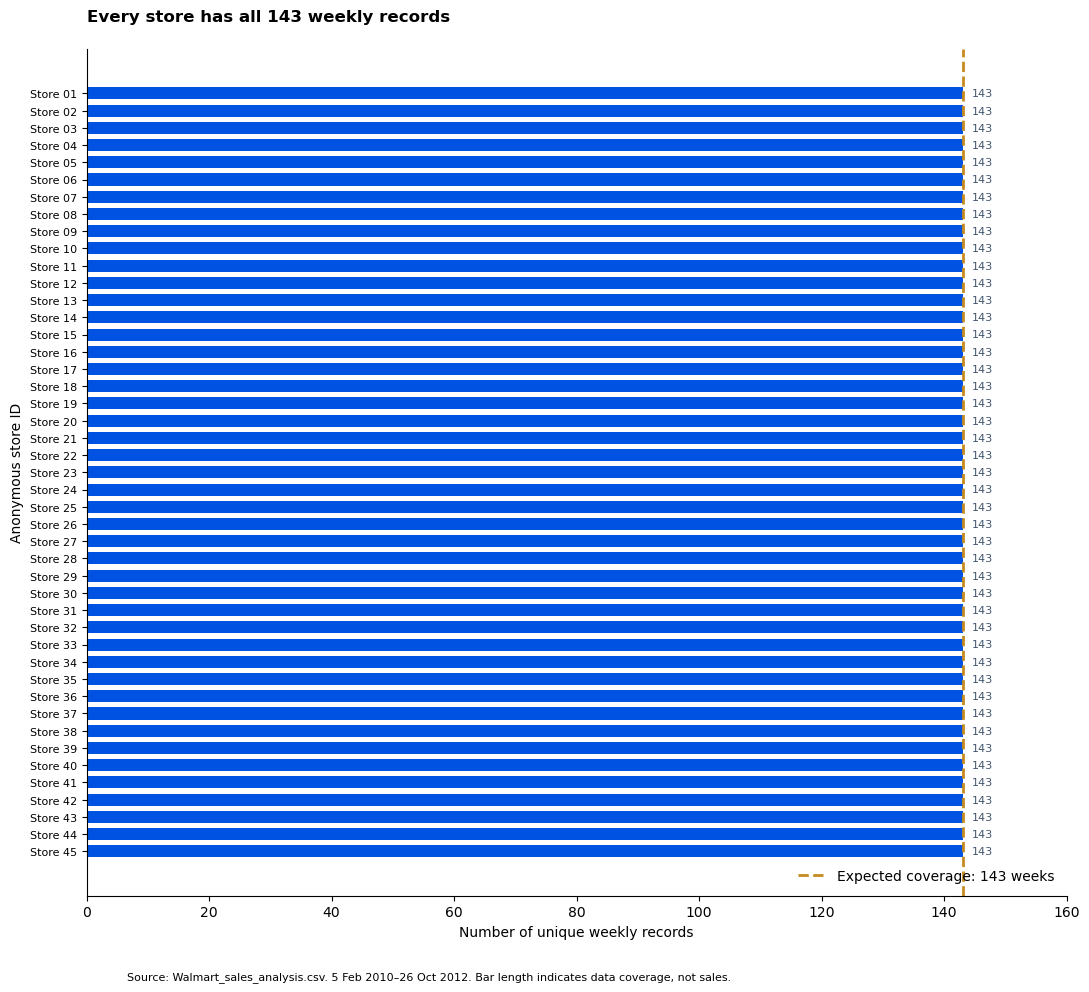

,Coverage status,Number of stores
0,All 143 weekly dates,45
1,Fewer than 143 weekly dates,0


Expected store-week records: 6,435
Observed unique store-week records: 6,435
Missing store-week combinations: 0
Repeated store-week combinations: 0
45 stores have complete coverage; 0 have incomplete coverage.


In [19]:
# Construct the same complete store-date matrix used for exact coverage checks
# A cell counts how often a store appears on one reported weekly date
store_order = sorted(df['Store_Number'].unique(), key=int)
coverage_matrix = (
    df.groupby(['Store_Number', 'Date']).size().unstack(fill_value=0)
    .reindex(index=store_order, columns=expected_dates, fill_value=0)
)

# Verify the complete set of dates, not just the total number of rows
expected_pairs = len(store_order) * len(expected_dates)
observed_pairs = int(coverage_matrix.gt(0).sum().sum())
missing_pairs = int(coverage_matrix.eq(0).sum().sum())
repeated_pairs = int(coverage_matrix.gt(1).sum().sum())
assert expected_pairs == 6435
assert observed_pairs == expected_pairs
assert missing_pairs == 0
assert repeated_pairs == 0

# Count unique weekly dates for each store
# These values answer a simpler visual question than a dense coverage heatmap
weekly_records_by_store = coverage_matrix.gt(0).sum(axis=1)
complete_stores = int(weekly_records_by_store.eq(len(expected_dates)).sum())
incomplete_stores = int(weekly_records_by_store.lt(len(expected_dates)).sum())

# Draw one horizontal bar for each of the 45 stores
# Bar length represents the number of weekly records, not sales performance
positions = list(range(len(store_order)))
fig, ax = plt.subplots(figsize=(11, 10))
ax.barh(positions, weekly_records_by_store.values,
        color='#0053E2', height=0.7)
ax.axvline(len(expected_dates), color='#C58B20', linewidth=2,
           linestyle='--', label='Expected coverage: 143 weeks')

# Show every store ID and label the bar endpoints
ax.set_yticks(positions)
ax.set_yticklabels([f'Store {int(store):02d}' for store in store_order], fontsize=8)
ax.invert_yaxis()
for position, weeks in zip(positions, weekly_records_by_store.values):
    ax.text(weeks + 1.5, position, str(weeks), va='center', fontsize=8, color='#42556C')
ax.set_xlim(0, 160)
ax.set_xlabel('Number of unique weekly records')
ax.set_ylabel('Anonymous store ID')
ax.set_title('Every store has all 143 weekly records', loc='left',
             fontweight='bold', pad=20)
ax.legend(frameon=False, loc='lower right')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
fig.text(0.12, 0.015,
         'Source: Walmart_sales_analysis.csv. 5 Feb 2010–26 Oct 2012. '
         'Bar length indicates data coverage, not sales.', fontsize=8)
fig.tight_layout(rect=[0, 0.04, 1, 1])
Path('figures').mkdir(exist_ok=True)
fig.savefig('figures/A1_weekly_records_by_store.png', dpi=180, bbox_inches='tight')
plt.show()

# Display the compact summary used in the PowerPoint
# 45 complete stores and 0 incomplete stores are directly calculated from the bars
coverage_summary = pd.DataFrame({
    'Coverage status': ['All 143 weekly dates', 'Fewer than 143 weekly dates'],
    'Number of stores': [complete_stores, incomplete_stores]
})
display(coverage_summary)
print(f'Expected store-week records: {expected_pairs:,}')
print(f'Observed unique store-week records: {observed_pairs:,}')
print(f'Missing store-week combinations: {missing_pairs}')
print(f'Repeated store-week combinations: {repeated_pairs}')
print(f'{complete_stores} stores have complete coverage; {incomplete_stores} have incomplete coverage.')

# Equal record counts alone do not prove that the stores cover the same dates
# Steps 6 and 9 also verify the date sequence and exact store-date combinations
# Coverage completeness does not establish original collection accuracy or representativeness

#### Key Findings — Coverage Completeness

- **Complete stores:** all 45 stores have 143 unique weekly records.
- **Missing store-week combinations:** none of the expected 6,435 combinations is missing.
- **Repeated combinations:** no store-date key is counted more than once.

**Interpretation.** Subsequent store comparisons cover the same dates, while weekly sample averages consistently represent the same 45 stores. The flat coverage profile is evidence about the panel structure, not evidence that the stores have similar sales.

**Limitation.** Equal record counts alone would not establish identical dates; the explicit date-sequence and store-date checks provide that additional verification. Broader source and sampling limits are stated in A.12.

**Key takeaway:** the file contains a balanced panel with no missing or repeated store-week combinations.


### A.10 Visual Evidence: Mean and Median Weekly Sales

The pooled sales histogram is evaluated alongside its mean and median. The mean incorporates the magnitude of every value; the median identifies the central ordered observation. Comparing the two helps assess whether a single overall average adequately represents the distribution.

The distribution combines variation between stores and variation over time. Its summaries should therefore be interpreted as pooled **store-week** measures, rather than the sales level of a particular store.


,Measure,Value
0,Mean weekly store sales,1046964.88
1,Median weekly store sales,960746.00
2,Mean minus median,86218.88
3,Mean above median (%),8.97
4,Sample skewness,0.67
5,IQR-flagged observations,34.00
6,Records removed,0.00


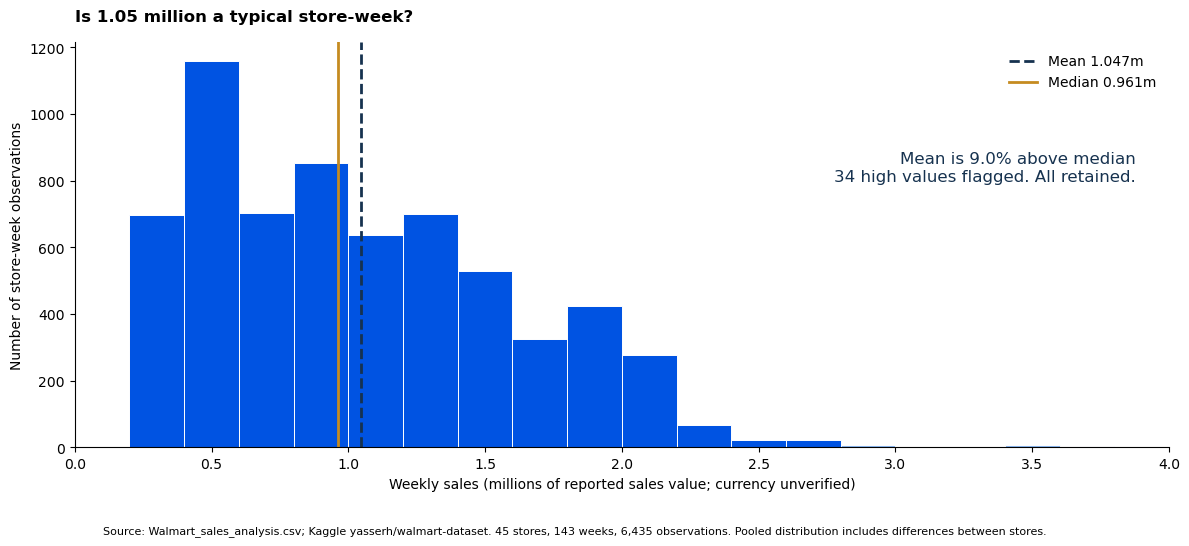

Mean sales: 1,046,964.88
Median sales: 960,746
Mean minus median: 86,218.88
Mean is 9.0% above the median.
Skewness: 0.67
Higher sales values pull up the mean, so we report both mean and median.
34 high values are statistical flags, not established recording errors. All are retained.


In [22]:
# Compare two summaries of the pooled store-week sales distribution
# The mean uses every value; the median is the midpoint of the ordered observations
mean_sales = df['Weekly_Sales'].mean()
median_sales = df['Weekly_Sales'].median()
mean_median_gap = mean_sales - median_sales
mean_median_gap_percent = mean_median_gap / median_sales * 100
sales_skewness = df['Weekly_Sales'].skew()

# Record the comparison in a table that is easy to check against the presentation
typical_sales_summary = pd.DataFrame({
    'Measure': ['Mean weekly store sales', 'Median weekly store sales',
                'Mean minus median', 'Mean above median (%)', 'Sample skewness',
                'IQR-flagged observations', 'Records removed'],
    'Value': [mean_sales, median_sales, mean_median_gap, mean_median_gap_percent,
              sales_skewness, len(extreme_sales), 0]
})
display(typical_sales_summary.round(2))

# Convert only the plotting values to millions; the original sales column stays unchanged
sales_million = df['Weekly_Sales'] / 1_000_000
mean_million = mean_sales / 1_000_000
median_million = median_sales / 1_000_000

# Use the same 0.2-million bins in the Notebook and PowerPoint
# The full observed range is included without clipping the high sales tail
bin_edges = [i / 5 for i in range(21)]
fig, ax = plt.subplots(figsize=(12, 5.5))
counts, edges, bars = ax.hist(sales_million, bins=bin_edges,
                            color='#0053E2', edgecolor='white', linewidth=0.7)

# Lighten bins beginning above the pooled IQR upper fence to make the right tail visible
# The colour is a visual guide only: exact flagged rows come from the individual-value rule in Step 8
# A threshold can fall inside a bin, so the highlighted bins are not a count of all flagged records
for left_edge, bar in zip(edges[:-1], bars):
    if left_edge >= upper_limit / 1_000_000:
        bar.set_facecolor('#8BB9F3')

# Add labelled mean and median reference lines
ax.axvline(mean_million, color='#16324F', linewidth=2, linestyle='--',
           label=f'Mean {mean_million:.3f}m')
ax.axvline(median_million, color='#C58B20', linewidth=2,
           label=f'Median {median_million:.3f}m')
ax.set_title('Is 1.05 million a typical store-week?', loc='left', fontweight='bold', pad=15)
ax.set_xlabel('Weekly sales (millions of reported sales value; currency unverified)')
ax.set_ylabel('Number of store-week observations')
ax.set_xlim(0, 4)
ax.legend(frameon=False, loc='upper right')
ax.text(0.97, 0.73, f'Mean is {mean_median_gap_percent:.1f}% above median\n'
        f'{len(extreme_sales)} high values flagged. All retained.',
        transform=ax.transAxes, ha='right', va='top', color='#16324F', fontsize=12)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
fig.text(0.09, 0.02,
         'Source: Walmart_sales_analysis.csv; Kaggle yasserh/walmart-dataset. '
         '45 stores, 143 weeks, 6,435 observations. Pooled distribution includes differences between stores.',
         fontsize=8)
fig.tight_layout(rect=[0, 0.07, 1, 1])
fig.savefig('figures/A2_mean_and_median_sales.png', dpi=200, bbox_inches='tight')
plt.show()

# Check that every original record is represented in the histogram
assert int(sum(counts)) == len(df)
print(f'Mean sales: {mean_sales:,.2f}')
print(f'Median sales: {median_sales:,.0f}')
print(f'Mean minus median: {mean_median_gap:,.2f}')
print(f'Mean is {mean_median_gap_percent:.1f}% above the median.')
print(f'Skewness: {sales_skewness:.2f}')
print('Higher sales values pull up the mean, so we report both mean and median.')
print(f'{len(extreme_sales)} high values are statistical flags, not established recording errors. All are retained.')

# A 9% gap provides different perspectives on the data; it does not make the mean invalid
# This is the median store-week observation, not the median long-run store average
# The pooled histogram cannot separate store differences from seasonal variation

#### Key Findings — Typical Sales and Distribution Shape

- **Mean weekly store sales:** approximately **1.047 million**.
- **Median weekly store sales:** approximately **0.961 million**.
- **Mean–median gap:** approximately **86,219**, with the mean **9.0% above** the median.
- **Sample skewness:** approximately **0.67**, consistent with a right-skewed pooled distribution.

**Interpretation.** Larger sales values raise the mean above the midpoint of the ordered observations. The mean remains informative about the sample average, while the median provides complementary context for what is typical. The difference motivates examining both store-level rankings and selected distributions in Module C.

**Limitation.** The pooled shape combines between-store differences and within-store movements. It cannot attribute the upper tail to a particular cause, and a high value is not necessarily an error.

**Key takeaway:** the overall average should be reported with the median and distributional evidence.


### A.11 Shared Variables and Holiday Classification

Calendar fields are created from the validated dates for grouping by year, month, quarter and year-month. ISO week and ISO year are retained together because their year boundaries may differ from calendar years. `Sales_Million` is a presentation scale; it does not replace the original numeric sales series.

Event names are inferred from the ten flagged dates using the competition context in Reference [2] and checked against the supplied file. The mapping is checked against the original binary indicator rather than used to redefine it. The label **Christmas-related** is used consistently for the December 30/31 flagged weeks. It does not identify the highest-selling pre-Christmas weeks.

The shared `clean_df` preserves every observation and provides consistent source fields for the subsequent analyses.


In [25]:
# Extract the calendar year, month, month name, and quarter from Date
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month
df['Month_Name'] = df['Date'].dt.month_name()
df['Quarter'] = df['Date'].dt.quarter

# Calculate ISO week and ISO year together
# ISO year can differ from calendar year near New Year, so both fields are retained
df['ISO_Week'] = df['Date'].dt.isocalendar().week.astype(int)
df['ISO_Year'] = df['Date'].dt.isocalendar().year.astype(int)

# Create a year-month label for grouping observations chronologically
df['Year_Month'] = df['Date'].dt.strftime('%Y-%m')

# Create a sales field scaled to millions for graph labels
# Keep Weekly_Sales in its original numeric scale for all calculations
df['Sales_Million'] = df['Weekly_Sales'] / 1_000_000

# Map only the flagged dates to holiday types for Module D
# These names are inferred from dates, not supplied as an original CSV field
# Mapping follows the group guide and the holiday-week list in the original Kaggle competition
# Reference: https://www.kaggle.com/c/walmart-recruiting-store-sales-forecasting/data
holiday_mapping = {
    '2010-02-12': 'Super Bowl', '2011-02-11': 'Super Bowl', '2012-02-10': 'Super Bowl',
    '2010-09-10': 'Labor Day', '2011-09-09': 'Labor Day', '2012-09-07': 'Labor Day',
    '2010-11-26': 'Thanksgiving', '2011-11-25': 'Thanksgiving',
    '2010-12-31': 'Christmas-related', '2011-12-30': 'Christmas-related'
}

# Display the full mapping so the label construction can be reviewed
holiday_mapping_table = pd.DataFrame({
    'Date': pd.to_datetime(list(holiday_mapping.keys())),
    'Inferred holiday type': list(holiday_mapping.values())
}).sort_values('Date')
display(holiday_mapping_table)

# Match each date to its inferred holiday type
inferred_labels = df['Date'].dt.strftime('%Y-%m-%d').map(holiday_mapping)

# Verify the mapping against the original Holiday_Flag before filling other rows
assert inferred_labels[df['Holiday_Flag'] == 1].notna().all(), 'Review unmapped flagged dates.'
assert inferred_labels[df['Holiday_Flag'] == 0].isna().all(), 'Mapping conflicts with Holiday_Flag.'

# Label unflagged weeks without claiming that they contain no holidays
# Preserve Holiday_Flag exactly as it was supplied
df['Holiday_Label'] = inferred_labels.fillna('Not holiday-labelled')

# Use the shared name clean_df for the final cleaned and prepared dataset
# The simpler name df remains available for code written in the style of Module B
clean_df = df.copy()
display(clean_df.head())

# Confirm that no observations were lost and no missing values were introduced
assert len(clean_df) == len(raw_df)
assert clean_df.isna().sum().sum() == 0
print('Final clean_df shape:', clean_df.shape)


,Date,Inferred holiday type
0,2010-02-12,Super Bowl
3,2010-09-10,Labor Day
6,2010-11-26,Thanksgiving
8,2010-12-31,Christmas-related
1,2011-02-11,Super Bowl
4,2011-09-09,Labor Day
7,2011-11-25,Thanksgiving
9,2011-12-30,Christmas-related
2,2012-02-10,Super Bowl
5,2012-09-07,Labor Day


,Store_Number,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment,Year,Month,Month_Name,Quarter,ISO_Week,ISO_Year,Year_Month,Sales_Million,Holiday_Label
0,1,2010-02-05,1643691.0,0,42.31,2.572,211,8.106,2010,2,February,1,5,2010,2010-02,1.643691,Not holiday-labelled
1,1,2010-02-12,1641957.0,1,38.51,2.548,211,8.106,2010,2,February,1,6,2010,2010-02,1.641957,Super Bowl
2,1,2010-02-19,1611968.0,0,39.93,2.514,211,8.106,2010,2,February,1,7,2010,2010-02,1.611968,Not holiday-labelled
3,1,2010-02-26,1409728.0,0,46.63,2.561,211,8.106,2010,2,February,1,8,2010,2010-02,1.409728,Not holiday-labelled
4,1,2010-03-05,1554807.0,0,46.50,2.625,211,8.106,2010,3,March,1,9,2010,2010-03,1.554807,Not holiday-labelled


Final clean_df shape: (6435, 17)


### A.12 Module Conclusions, Limitations and Data Handover

#### Main Findings

- **Complete and unique coverage:** all 45 stores are observed on the same 143 dates, giving 6,435 unique store-week records.
- **No required deletion or imputation:** the supplied file passes the missing-value, conversion, duplicate-key and flag checks.
- **An overall mean requires context:** mean sales exceed the pooled median by approximately 9.0%, supporting the use of distributional and store-level evidence alongside the average.
- **Extreme observations are retained:** the 34 IQR-flagged values are statistical flags, not established data errors.

#### Limitations

1. **Historical and restricted sample.** The 45 anonymous stores cannot be assumed to represent the entire Walmart business or current conditions.
2. **Incomplete calendar years.** The file contains 48 observed weeks in 2010, 52 in 2011 and 43 in 2012. Direct annual totals would mix sales differences with unequal coverage.
3. **Missing explanatory information.** Store location, size, type, footfall, promotions, costs and profits are unavailable. Sales differences alone do not establish their causes or profitability.
4. **Measurement and source uncertainty.** Original units and file lineage remain partly unverified. Internal completeness cannot establish collection accuracy or restore absent precision.
5. **Limited indicator coverage and dependent observations.** The holiday flag identifies selected dates, and observations share stores and dates. Descriptive associations do not establish causality.

#### Handover

The cleaned dataset and supporting evidence are exported for reproducibility. Module B examines average weekly sales over time, Module C compares typical store sales and relative variation, and Module D evaluates the original holiday indicator. The input CSV remains unchanged.

**Key takeaway:** the supplied panel provides a consistent basis for descriptive comparisons, while source verification and interpretation limits remain distinct from data completeness.


In [27]:
# Document calendar-year coverage before interpreting annual patterns.
year_coverage = df.groupby('Year').agg(
    First_date=('Date', 'min'), Last_date=('Date', 'max'),
    Unique_weeks=('Date', 'nunique'), Observations=('Date', 'size')
)
display(year_coverage)

# Export the common cleaned dataset without modifying the source CSV.
# The historical sample and missing store characteristics limit generalisation and causal claims.
clean_df.to_csv('Walmart_clean.csv', index=False, date_format='%Y-%m-%d')
print('Cleaned data saved as Walmart_clean.csv')

# Report calculated sample and sales summaries for consistency with the presentation.
print(f"Sample: {len(df):,} observations, {df['Store_Number'].nunique()} stores, "
      f"{df['Date'].nunique()} weekly dates.")
print(f'Missing source-field values: {missing_values.sum()}; duplicate store-date keys: {duplicate_store_dates}.')
print(f"Average weekly store sales: {df['Weekly_Sales'].mean():,.2f}; "
      f"median: {df['Weekly_Sales'].median():,.0f}.")
print('All original records and extreme sales values are retained for the next modules.')

# Export chart evidence from the same calculations rather than entering slide values manually.
coverage_matrix.to_csv('coverage_matrix.csv', index_label='Store_Number', date_format='%Y-%m-%d')
summary_statistics.to_csv('summary_statistics.csv')
typical_sales_summary.to_csv('typical_sales_summary.csv', index=False)
slide_evidence = {
    'rows': int(len(df)), 'stores': int(df['Store_Number'].nunique()),
    'weeks': int(df['Date'].nunique()), 'missing_values': int(missing_values.sum()),
    'duplicate_store_weeks': int(duplicate_store_dates),
    'failed_conversions': int(sales_conversion_failures + date_conversion_failures),
    'expected_pairs': int(expected_pairs), 'observed_pairs': int(observed_pairs),
    'missing_pairs': int(missing_pairs), 'repeated_pairs': int(repeated_pairs),
    'mean': float(mean_sales), 'median': float(median_sales),
    'mean_median_gap': float(mean_median_gap),
    'mean_median_gap_percent': float(mean_median_gap_percent),
    'skewness': float(sales_skewness), 'iqr_flagged': int(len(extreme_sales)),
    'iqr_upper_fence': float(upper_limit), 'records_removed': 0,
    'minimum': float(df['Weekly_Sales'].min()), 'maximum': float(df['Weekly_Sales'].max()),
    'histogram_counts': [int(c) for c in counts], 'histogram_edges': [float(e) for e in edges],
    'store_ids': [int(s) for s in store_order],
    'coverage_values': coverage_matrix.astype(int).values.tolist(),
    'complete_stores': int(complete_stores), 'incomplete_stores': int(incomplete_stores),
    'weekly_records_by_store': {str(k): int(v) for k, v in weekly_records_by_store.items()},
    'date_labels': [d.strftime('%Y-%m-%d') for d in expected_dates],
}
# Retain the underlying evidence alongside the summary tables for reproducibility.
Path('slide_evidence.json').write_text(json.dumps(slide_evidence, indent=2), encoding='utf-8')
print('Slide evidence exported. The presentation and Notebook use the same calculated values.')

# Provide a compact coverage summary in addition to the full store-date matrix.
coverage_summary.to_csv('coverage_summary.csv', index=False)


,First_date,Last_date,Unique_weeks,Observations
Year,,,,
2010,2010-02-05,2010-12-31,48,2160
2011,2011-01-07,2011-12-30,52,2340
2012,2012-01-06,2012-10-26,43,1935


Cleaned data saved as Walmart_clean.csv
Sample: 6,435 observations, 45 stores, 143 weekly dates.
Missing source-field values: 0; duplicate store-date keys: 0.
Average weekly store sales: 1,046,964.88; median: 960,746.
All original records and extreme sales values are retained for the next modules.
Slide evidence exported. The presentation and Notebook use the same calculated values.


## Module B: Sales Trends and Seasonality


**Research question:** Are recurring seasonal peaks more pronounced than year-to-year changes in average weekly sales?

This module examines three complementary views of the historical sales series: weekly movements, monthly seasonality and yearly averages over a common calendar period. It uses the validated data and calendar fields prepared in Module A.

Average weekly sales per store are used to distinguish sales levels from totals affected by the number of observations. A trailing four-week moving average provides a descriptive smoother. The yearly comparison is restricted to February–October to reduce the effect of incomplete annual coverage; it is not a formal seasonal adjustment or a growth model.


### B.1 Average Weekly Sales Across Stores

For each date, sales are averaged across the same 45 stores. The resulting series contains 143 weekly observations, each representing average sales per store rather than combined sales across the sample. The unsmoothed chart establishes the weekly series; the following overlay adds the four-week smoother while retaining the original observations.

Because store coverage is constant, movements in this series are not explained by stores entering or leaving the dataset. However, the average can still conceal differences in how individual stores respond over time.


In [31]:
# Use the validated panel and calendar fields from Module A.
# Each date contains the same 45 stores, so the mean describes average sales per store.
# This is not the combined weekly sales total across all stores.
weekly = df.groupby('Date')['Weekly_Sales'].mean()

weekly.head()


Date
2010-02-05    1.105572e+06
2010-02-12    1.074148e+06
2010-02-19    1.072822e+06
2010-02-26    9.770794e+05
2010-03-05    1.041588e+06
Name: Weekly_Sales, dtype: float64

### B.2 Weekly Sales Trends

The first line chart displays the full sequence of weekly averages without smoothing. This preserves the timing and magnitude of individual peaks and troughs. The next chart adds a moving average to distinguish short-term fluctuations from recurring broader movements.


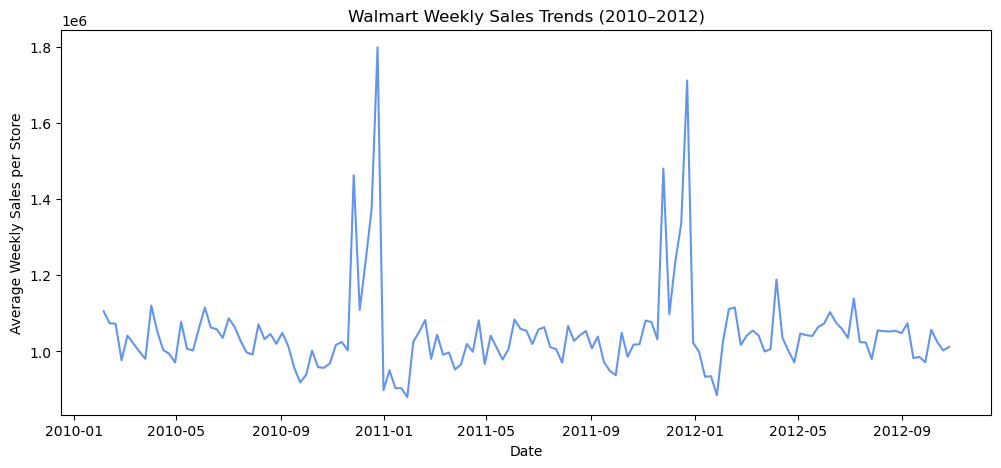

In [33]:
# Plot the complete sequence of weekly store averages before applying smoothing.
# The vertical axis retains the original reported sales scale.
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(weekly.index, weekly.values, color='cornflowerblue')

ax.set_title('Walmart Weekly Sales Trends (2010–2012)')

ax.set_xlabel('Date')

ax.set_ylabel('Average Weekly Sales per Store')

plt.show()


#### Four-Week Moving Average

Each smoothed value averages the current week and the preceding three weeks. The first three dates have no complete four-week window and therefore no smoothed value. The raw series remains visible so that smoothing does not conceal individual sales peaks.

The moving average summarises historical observations. It does not estimate a causal seasonal effect, establish a statistically significant trend or provide an out-of-sample forecast.


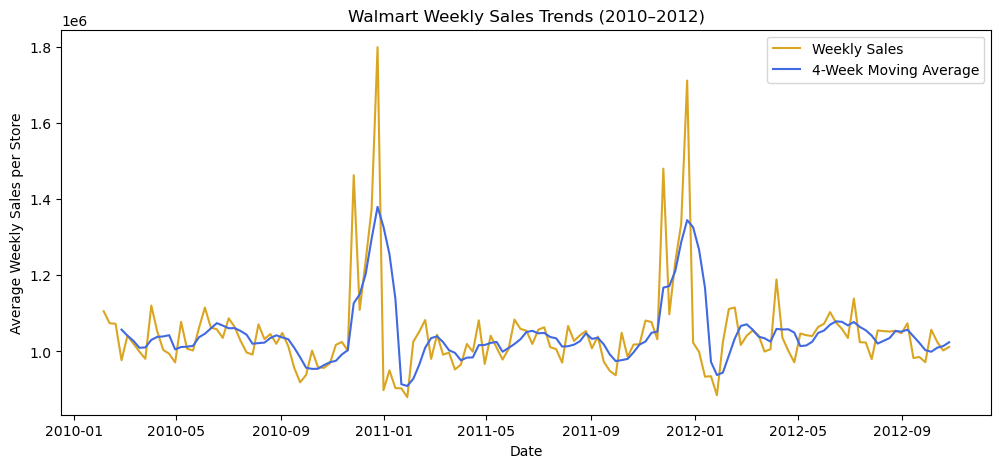

In [35]:
# Calculate a trailing four-week mean using the current and preceding three weeks.
# The first three dates lack a complete window and remain missing in the smoothed series.
# The smoother describes historical movements and is not a forecast.
moving_average = weekly.rolling(4).mean()

fig, ax = plt.subplots(figsize=(12, 5))

# Overlay the unsmoothed observations to preserve the size and timing of the weekly peaks.
ax.plot(weekly.index, weekly.values,color='goldenrod', label='Weekly Sales')

# Show the smoothed series on the same axes for direct comparison.
ax.plot(moving_average.index, moving_average.values,color='royalblue', label='4-Week Moving Average')

ax.set_title('Walmart Weekly Sales Trends (2010–2012)')

ax.set_xlabel('Date')
ax.set_ylabel('Average Weekly Sales per Store')

ax.legend()

plt.show()


#### Key Findings — Weekly Sales Trends

The weekly series contains pronounced year-end peaks:

- **24 December 2010:** average weekly sales reach approximately **1.80 million per store**, the highest value in the sample.
- **23 December 2011:** average weekly sales reach approximately **1.71 million per store**, the second-highest value.
- **Recurring timing:** the four-week moving average also rises toward year-end, showing that the pattern extends beyond a single isolated observation.

**Interpretation.** The most visible feature is recurring peak activity near year-end. Outside these episodes, the graph does not display a similarly clear sustained upward movement. Monthly and comparable-period yearly summaries provide further context for this visual interpretation.

**Limitation.** Only two year-end periods are observed, and no formal trend or seasonal model is estimated. The apparent recurrence should therefore be assessed within this short historical series.

**Key takeaway:** pronounced year-end peaks dominate the visible weekly pattern within the observed period.


### B.3 Average Weekly Sales per Store by Calendar Month

Store-week observations are pooled by calendar month, and average weekly sales are calculated for each month. This compares sales levels rather than monthly totals, which would also depend on the number of available observations.

November and December are highlighted to connect the monthly comparison with the peaks in the weekly series. The calculation does not equalise the mix of years or weekly dates represented by each month.


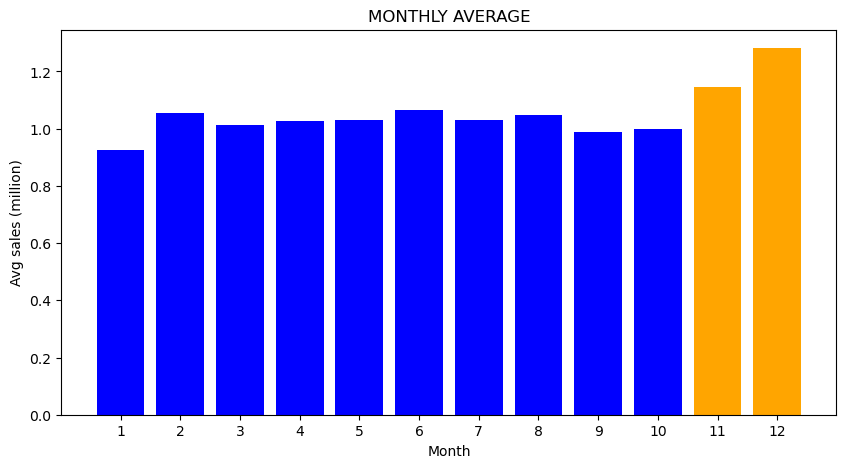

In [38]:
# Pool the observed store-week sales by calendar month using the Month field from Module A.
# Averages avoid comparing monthly totals with different observation counts.
# Available years still differ across months; this does not fully adjust for calendar coverage.
monthly = df.groupby('Month')['Weekly_Sales'].mean()

# Scale plotting values to millions without altering the source sales column.
monthly = monthly / 1000000

fig, ax = plt.subplots(figsize=(10, 5))

# Highlight November and December to link the monthly pattern to the weekly year-end peaks.
colors = ['blue'] * 10 + ['orange'] * 2

ax.bar(monthly.index, monthly.values, color=colors)

ax.set_title('MONTHLY AVERAGE')

ax.set_xlabel('Month')

ax.set_ylabel('Avg sales (million)')

ax.set_xticks(range(1, 13))

plt.show()


#### Key Findings — Monthly Seasonality

The monthly comparison shows clear differences in average weekly sales across the observed calendar months:

- **December:** the highest average, approximately **1.28 million per store**.
- **November:** the second-highest average, approximately **1.15 million per store**.
- **January:** the lowest average, approximately **0.92 million per store**.

**Interpretation.** The higher November and December averages reinforce the year-end pattern in the weekly charts. January has the lowest observed sales level, providing a complementary view of the variation around year-end.

**Limitation.** Monthly coverage is uneven because the sample runs from February 2010 to October 2012. November and December contain 2010 and 2011 observations, while January contains 2011 and 2012 observations. Consequently, the comparison describes the available sample rather than three complete annual cycles or a fully adjusted seasonal effect.

**Key takeaway:** year-end months have the strongest observed average sales, with December recording the highest value.


### B.4 Highest- and Lowest-Selling Weeks

Weekly averages are ranked to identify the dates underlying the main peaks and troughs. The ranking is across dates after averaging all stores; it is distinct from ranking individual store-week observations.

These dates also connect the time-pattern analysis to Module D, where the largest December peaks are compared with the provider's holiday labels.


In [41]:
# Rank the weekly averages, rather than individual store-week sales.
# The first and last five entries identify the strongest and weakest dates in the aggregate series.
# The late-December peaks are checked against Holiday_Flag in Module D.
weekly_sorted = weekly.sort_values(ascending=False)

print('Top 5 Sales Weeks:')
print(weekly_sorted.head())

print('Bottom 5 Sales Weeks:')
print(weekly_sorted.tail())


Top 5 Sales Weeks:
Date
2010-12-24    1.798476e+06
2011-12-23    1.711072e+06
2011-11-25    1.479858e+06
2010-11-26    1.462689e+06
2010-12-17    1.373795e+06
Name: Weekly_Sales, dtype: float64
Bottom 5 Sales Weeks:
Date
2011-01-14    903859.577778
2011-01-21    903436.622222
2010-12-31    898500.444444
2012-01-27    885221.644444
2011-01-28    879996.733333
Name: Weekly_Sales, dtype: float64


#### Key Findings — Peak and Trough Dates

The top five weekly averages include the two pre-Christmas peaks, the Thanksgiving-labelled dates in November 2010 and 2011, and 17 December 2010. The five lowest averages fall in late December or January; 28 January 2011 has the lowest sample-wide weekly average, approximately 0.880 million per store.

**Interpretation.** The ranked dates reinforce the concentration of high sales toward year-end and show that adjacent weeks can have substantially different sales levels. A broad seasonal label therefore does not replace attention to the exact reported week.

**Limitation.** These selected extremes describe the observed dates; their ordering may change with a longer sample.

**Key takeaway:** precise dates matter when linking seasonal sales patterns to holiday labels.


### B.5 Comparable-Period Yearly Averages

The yearly comparison is restricted to February–October, a calendar period present in all three years. Mean weekly store sales are used instead of annual totals to avoid differences driven mechanically by unequal numbers of observed weeks.

This improves comparability but does not create perfectly matched calendar weeks. The number and placement of weekly dates can still differ, and the filter excludes the November–December peaks from every year.


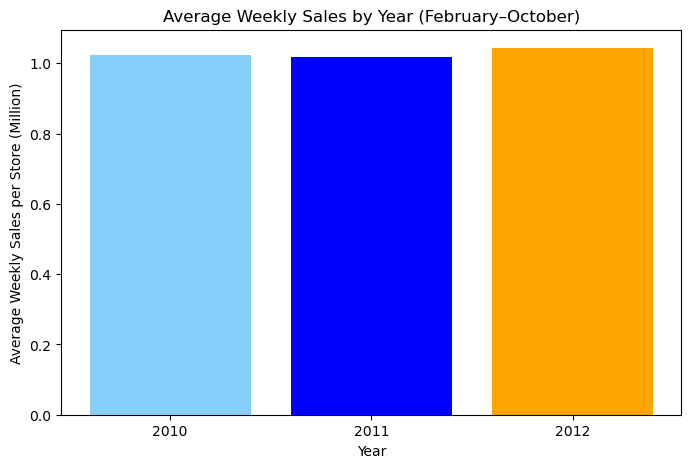

In [44]:
# Restrict comparisons to February-October, which is observed in each available year.
# This avoids comparing incomplete annual totals; exact weekly dates can still differ.
common_months = df[(df['Month'] >= 2) & (df['Month'] <= 10)]

# Calculate mean store-week sales within the common calendar period for each year.
yearly = common_months.groupby('Year')['Weekly_Sales'].mean()

# Convert only the displayed yearly averages to millions.
yearly = yearly / 1000000

fig, ax = plt.subplots(figsize=(8, 5))

colors = ['lightskyblue', 'blue', 'orange']

# Use a common vertical scale to compare the three descriptive yearly averages.
ax.bar(yearly.index, yearly.values, color=colors)

ax.set_title('Average Weekly Sales by Year (February–October)')

ax.set_xlabel('Year')

ax.set_ylabel('Average Weekly Sales per Store (Million)')

ax.set_xticks([2010, 2011, 2012])

plt.show()


#### Key Findings — Yearly Comparison

Average weekly sales per store during February–October are:

- **2010:** approximately **1.024 million**.
- **2011:** approximately **1.018 million**.
- **2012:** approximately **1.043 million**.

The highest average is approximately **2.5% above the lowest**, using the lowest yearly average as the denominator.

**Interpretation.** Average sales levels remain relatively close across the three common-period samples. Although 2012 has the highest average, these differences are modest compared with the pronounced movements around the observed year-end peaks. This supports distinguishing recurring peak activity from broad year-to-year change.

**Limitation.** The common calendar range excludes November–December and is not a complete seasonal adjustment. These averages therefore describe February–October rather than full-year performance.

**Key takeaway:** common-period yearly averages differ relatively little within this historical sample.


### B.6 Module Conclusions and Limitations


#### Main Findings

1. **Recurring year-end peaks:** the two highest weekly averages occur immediately before Christmas in 2010 and 2011.
2. **Stronger year-end monthly averages:** December and November have the highest observed sales levels, while January has the lowest.
3. **Modest comparable-period yearly differences:** February–October averages range from approximately 1.018 million to 1.043 million per store-week.

Taken together, the views provide a consistent descriptive answer to the research question: seasonal peaks are more prominent in the observed series than the differences between common-period yearly averages.

#### Limitations and Transition

The principal module-specific constraint is calendar comparability: only two year-end periods are observed, and the common-period yearly comparison excludes those peak months. The figures establish a descriptive time pattern, while source scope and causal limits are consolidated under Study-Wide Limitations.

The aggregate series also conceals the distribution of sales across stores. Module C therefore examines whether stores with high typical sales also display low relative variability.

**Key takeaway:** the time dimension reveals recurring peaks, but it cannot by itself describe store-level performance or explain seasonal causes.


## Module C: Store Sales Performance and Relative Stability

**Research question:** How large are the differences in typical store sales, and are the highest-selling stores also the most stable in relative terms?

This module separates two dimensions of performance: **sales level**, described primarily by mean and median weekly sales, and **relative variability**, measured using the coefficient of variation (CV). It combines rankings, a full-sample scatterplot and selected sales distributions.

Stability is defined narrowly as a lower historical CV. It does not imply greater profitability, better management, lower forecast error or operational reliability. Sales figures are expressed in millions of reported sales value where indicated.


In [49]:
# Export figures and the store-level summary for reproducibility.
EXPORT_RESULTS = True
# Keep exported results separate from the input data.
OUTPUT_DIR = Path("module_c_outputs")

if EXPORT_RESULTS:
    OUTPUT_DIR.mkdir(exist_ok=True)

BLUE = "#0053E2"
YELLOW = "#FFC220"
INK = "#16324F"
GREY = "#61768B"
PALE_BLUE = "#A9DDF7"
# Set plotting defaults here; these also remain active for subsequent Module D figures.
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 11,
    "axes.titlesize": 16, "axes.titleweight": "bold",
    "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": GREY, "ytick.color": GREY,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.spines.left": False, "axes.spines.bottom": False,
    "figure.facecolor": "white", "axes.facecolor": "white",
    "savefig.facecolor": "white"
})


### C.1 Shared Data and Coverage Verification

The original source fields are copied from Module A's `clean_df`, and store identifiers are converted to integers locally for comparisons and labels. The shared cleaned dataset is not modified.

Source-field cleaning and validation occur upstream. The checks below confirm that each store still covers the complete set of weekly dates before store means, rankings and variability measures are compared. Sorting provides a reproducible ordering without changing the sample.


In [51]:
# Reuse the fields cleaned and validated in Module A, retaining a separate local copy.
# Integer store IDs are used locally; the shared clean_df identifiers remain unchanged.
c_raw = raw_df
c_data = clean_df[raw_df.columns.str.strip()].copy()
c_data["Store_Number"] = c_data["Store_Number"].astype(int)

# Sort observations for reproducibility without changing the analysis sample.
c_data = c_data.sort_values(["Store_Number", "Date"]).reset_index(drop=True)
# Verify that every store is observed over the same set of weekly dates.
c_coverage = c_data.groupby("Store_Number").agg(
    Observations=("Date", "size"), Unique_Weeks=("Date", "nunique"),
    First_Week=("Date", "min"), Last_Week=("Date", "max")
)
# Check coverage from the date perspective as well as the store perspective.
c_week_counts = c_data.groupby("Date")["Store_Number"].nunique()
c_n_stores = c_data["Store_Number"].nunique()
c_n_weeks = c_data["Date"].nunique()
# Combined with unique keys, these conditions establish identical date coverage.
c_balanced = (
    c_coverage["Unique_Weeks"].eq(c_n_weeks).all()
    and c_week_counts.eq(c_n_stores).all()
)
print(f"{len(c_data):,} records | {c_n_stores} stores | {c_n_weeks} weekly dates")
print(f"Coverage: {c_data.Date.min():%d %b %Y} to {c_data.Date.max():%d %b %Y}")
print("Same complete set of dates for every store:", bool(c_balanced))
# Display a coverage sample; the preceding validation includes every store.
display(c_coverage.head())
if not c_balanced:
    raise ValueError("Unequal coverage: agree on a common date sample before comparing stores.")


6,435 records | 45 stores | 143 weekly dates
Coverage: 05 Feb 2010 to 26 Oct 2012
Same complete set of dates for every store: True


,Observations,Unique_Weeks,First_Week,Last_Week
Store_Number,,,,
1,143,143,2010-02-05,2012-10-26
2,143,143,2010-02-05,2012-10-26
3,143,143,2010-02-05,2012-10-26
4,143,143,2010-02-05,2012-10-26
5,143,143,2010-02-05,2012-10-26


#### Key Findings — Comparable Store Coverage

- **45 stores** are included in the comparison.
- Each store contributes the same **143 weekly observations**.
- The total remains **6,435 store-week records**, covering identical dates for every store.

**Interpretation.** Differences in rankings are not driven by some stores having longer observation periods. With equal week counts, total sales and mean weekly sales produce the same ordering; the mean remains the main measure because it is easier to interpret as a typical weekly sales level.

**Limitation.** Identical coverage removes observation-length differences from this comparison; other store characteristics remain unobserved.

**Key takeaway:** store comparisons use a balanced historical panel.


### C.2 Store-Level Measures and Analytical Definitions

Weekly observations are aggregated to one row per store. The measures address different features of the sales distribution:

- **Mean weekly sales:** the primary measure of sales level.
- **Median weekly sales:** a complementary measure less sensitive to unusually high weeks.
- **Sample standard deviation (SD):** dispersion measured in the original sales units.
- **Coefficient of variation (CV):** dispersion relative to the store's mean sales level.
- **Total, minimum, maximum and range:** supporting summaries of the observed period.

For store $i$,

$$CV_i = \frac{s_i}{\bar{x}_i},$$

where $s_i$ is sample SD (`ddof=1`) and $\bar{x}_i$ is mean weekly sales. Positive means are checked before interpreting CV. The stored ratio 0.13 corresponds to 13%.

Sales rank 1 denotes the highest mean, whereas CV rank 1 denotes the lowest relative variability. This distinction prevents the two rankings from being interpreted as a single overall measure of store quality.


In [54]:
# Aggregate weekly observations to one row per store.
c_store_summary = c_data.groupby("Store_Number").agg(
    # Equal week counts make totals comparable; means remain the primary ranking measure.
    Weeks=("Weekly_Sales", "size"),
    Mean_Sales=("Weekly_Sales", "mean"),
    # Retain a measure of typical sales less sensitive to unusually large weeks.
    Median_Sales=("Weekly_Sales", "median"),
    Total_Sales=("Weekly_Sales", "sum"),
    SD_Sales=("Weekly_Sales", "std"),
    Min_Sales=("Weekly_Sales", "min"),
    Max_Sales=("Weekly_Sales", "max")
)
# Positive means are required for the relative-variability interpretation used here.
if c_store_summary["Mean_Sales"].le(0).any():
    raise ValueError("CV interpretation requires positive mean sales in this analysis.")
# Retain both absolute dispersion and scale-adjusted dispersion measures.
c_store_summary["Range_Sales"] = c_store_summary["Max_Sales"] - c_store_summary["Min_Sales"]
# pandas std uses the sample standard deviation (ddof=1).
c_store_summary["CV"] = c_store_summary["SD_Sales"] / c_store_summary["Mean_Sales"]
# Rank by mean sales, with store ID as a deterministic tie-breaker.
c_store_summary = c_store_summary.sort_values(
    ["Mean_Sales", "Store_Number"], ascending=[False, True]
)
# Number the sorted stores from the highest mean (rank 1) to the lowest.
c_store_summary["Mean_Rank"] = range(1, len(c_store_summary) + 1)
# Rank relative stability separately: rank 1 has the lowest CV.
# Shared ranks are retained if CV values are tied.
c_store_summary["CV_Rank"] = c_store_summary["CV"].rank(method="min").astype(int)
# Format displayed ratios as percentages while retaining full precision for calculations.
c_kpi_display = c_store_summary[["Weeks", "Mean_Sales", "Median_Sales",
                               "SD_Sales", "CV", "Mean_Rank", "CV_Rank"]].copy()
c_kpi_display["CV"] = c_kpi_display["CV"].map(lambda value: f"{value:.2%}")
display(c_kpi_display.round(2))

,Weeks,Mean_Sales,Median_Sales,SD_Sales,CV,Mean_Rank,CV_Rank
Store_Number,,,,,,,
20,143,2107676.89,2053165.0,275900.52,13.09%,1,23
4,143,2094712.96,2073951.0,266201.40,12.71%,2,22
14,143,2020978.40,2004330.0,317569.96,15.71%,3,33
13,143,2003620.33,1958824.0,265507.00,13.25%,4,24
2,143,1925751.34,1879107.0,237683.72,12.34%,5,17
10,143,1899424.57,1827522.0,302262.10,15.91%,6,34
27,143,1775216.22,1731935.0,239930.15,13.52%,7,26
6,143,1564728.17,1524390.0,212525.83,13.58%,8,27
1,143,1555264.43,1534850.0,155980.76,10.03%,9,8


#### Reading the Store Summary

The table places sales-level measures alongside absolute and relative dispersion. CV percentages are formatted for readability while the underlying calculations retain full precision. For example, Store 20 combines mean weekly sales of approximately 2.108 million with a CV of about 13.09%.

The next sections examine sales rankings and stability rankings separately. Keeping the measures side by side supports comparison without treating them as interchangeable indicators.


### C.3 Size of the Store Sales Gap

The five highest- and five lowest-selling stores are selected by mean weekly sales and displayed on a common horizontal scale. The highest-to-lowest ratio summarises the magnitude of the difference.

Mean- and median-based rank correlation provides a complementary sensitivity check: it assesses whether the broad sales ordering changes when the measure of typical sales is less influenced by upper-tail observations. It does not test temporal stability.


,Group,Mean_Sales,Median_Sales,CV
Store_Number,,,,
20,Top 5,2.107677e+06,2053165.0,0.1309
4,Top 5,2.094713e+06,2073951.0,0.1271
14,Top 5,2.020978e+06,2004330.0,0.1571
13,Top 5,2.003620e+06,1958824.0,0.1325
2,Top 5,1.925751e+06,1879107.0,0.1234
33,Bottom 5,2.598617e+05,258427.0,0.0929
44,Bottom 5,3.027488e+05,298080.0,0.0818
5,Bottom 5,3.180119e+05,310338.0,0.1187
36,Bottom 5,3.735120e+05,373268.0,0.1626


Highest / lowest mean weekly sales: 8.11 times
Correlation between mean and median rankings: 0.9987


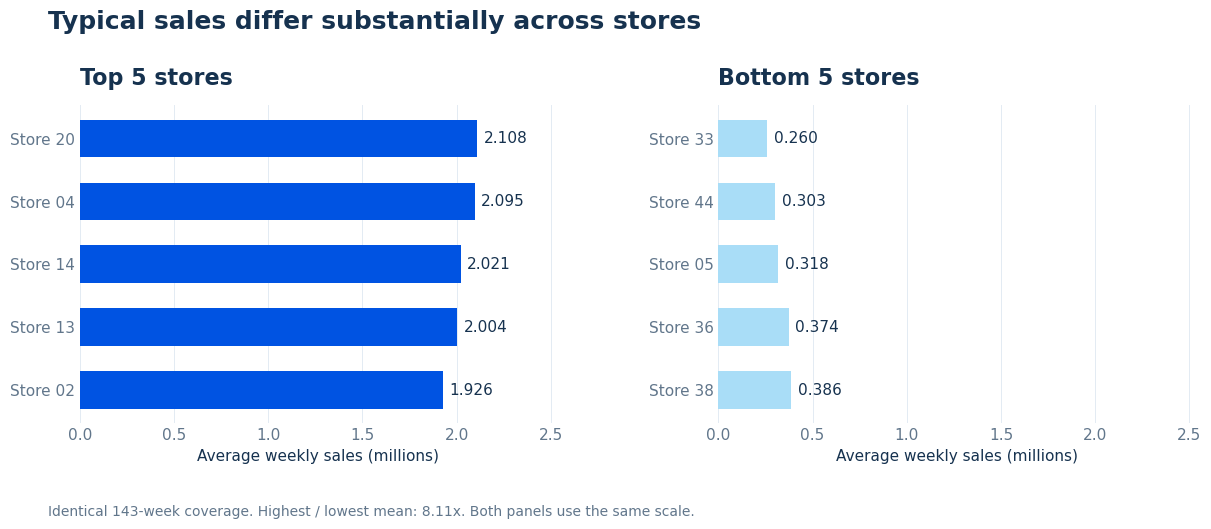

In [57]:
# Report both ends of the sales distribution rather than only the leading stores.
c_top5 = c_store_summary.head(5)
# Display the lowest-selling store first within the bottom group.
c_bottom5 = c_store_summary.tail(5).sort_values("Mean_Sales")
# This is a ratio of sales levels, not a percentage change over time.
c_gap = c_store_summary["Mean_Sales"].max() / c_store_summary["Mean_Sales"].min()
# Check whether the store ordering is sensitive to using the mean or median.
c_rank_corr = c_store_summary["Mean_Sales"].rank().corr(
    c_store_summary["Median_Sales"].rank()
)
display(pd.concat([
    c_top5.assign(Group="Top 5"), c_bottom5.assign(Group="Bottom 5")
])[["Group", "Mean_Sales", "Median_Sales", "CV"]].round(4))
print(f"Highest / lowest mean weekly sales: {c_gap:.2f} times")
print(f"Correlation between mean and median rankings: {c_rank_corr:.4f}")

# Use an identical horizontal scale for the top and bottom groups.
fig, axes = plt.subplots(1, 2, figsize=(12.6, 5.3), sharex=True)
for ax, table, title, colour in [
    (axes[0], c_top5, "Top 5 stores", BLUE),
    (axes[1], c_bottom5, "Bottom 5 stores", PALE_BLUE)
]:
    # Express plotted sales in millions; retain original units in the summary table.
    values = table["Mean_Sales"] / 1_000_000
    ax.barh(range(len(table)), values, color=colour, height=0.6)
    ax.set_yticks(range(len(table)), [f"Store {int(s):02d}" for s in table.index])
    # Preserve the intended rank order from top to bottom.
    ax.invert_yaxis()
    ax.set_title(title, loc="left", pad=15)
    ax.set_xlabel("Average weekly sales (millions)")
    ax.set_xlim(0, c_top5["Mean_Sales"].max() / 1_000_000 * 1.20)
    ax.xaxis.grid(True, color="#E3EBF3", linewidth=0.7)
    ax.set_axisbelow(True)
    ax.tick_params(length=0)
    # Add numeric labels so the size of each sales gap can be read directly.
    for j, value in enumerate(values):
        ax.text(value + 0.035, j, f"{value:.3f}", va="center", fontsize=11, color=INK)
fig.suptitle("Typical sales differ substantially across stores", x=0.06,
             ha="left", fontsize=18, fontweight="bold", color=INK)
fig.text(0.06, 0.025,
         f"Identical {c_n_weeks}-week coverage. Highest / lowest mean: {c_gap:.2f}x. Both panels use the same scale.",
         color=GREY, fontsize=10)
fig.subplots_adjust(left=0.085, right=0.97, top=0.80, bottom=0.20, wspace=0.34)
if EXPORT_RESULTS:
    # Export at a resolution suitable for reproducing the figure in the presentation.
    fig.savefig(OUTPUT_DIR / "C1_top_bottom_stores.png", dpi=220, bbox_inches="tight")
plt.show()


#### Key Findings — Store Sales Levels

- **Highest mean:** Store 20 averages approximately **2.108 million** in weekly sales, followed by Stores 4, 14, 13 and 2.
- **Lowest mean:** Store 33 averages approximately **0.260 million**.
- **Magnitude of the gap:** the highest mean is **8.11 times** the lowest.
- **Agreement between measures:** mean- and median-based rankings are closely aligned, with rank correlation approximately **0.999**.

**Interpretation.** A single pooled average conceals substantial differences between stores. The close ranking agreement indicates that the broad ordering is not highly sensitive to choosing the mean or median as the sales-level measure.

**Limitation.** Agreement between mean- and median-based rankings concerns sales levels, not weekly stability. Explanations of store differences require the additional characteristics discussed in the study-wide limitations.

**Key takeaway:** store sales levels differ substantially, and their ordering is broadly consistent across mean and median measures.


### C.4 Sales Leadership and Relative Stability

The scatterplot compares mean weekly sales and CV for all 45 stores, highlighting the five highest-selling stores. Dashed lines mark the median of store means and the median of store CVs. They provide descriptive reference points, not targets or externally validated performance thresholds.

Two complementary checks address the research question:

1. **Rank overlap:** compare the five highest-selling stores with the five stores having the lowest CV.
2. **Full-sample association:** calculate Pearson correlations of mean sales with CV and with absolute SD.

The top-five cutoff is a descriptive choice, and Pearson correlation measures linear association only. Neither calculation is presented as a statistical significance test or evidence of causality.


Median of store means: 0.967 million
Median store CV: 13.09%
Mean sales versus CV, Pearson r = 0.137
Mean sales versus absolute SD, Pearson r = 0.928
Overlap between top-five sales and lowest-five CV: 0 of 5 stores
Lowest-CV stores: Store 37, Store 30, Store 43, Store 44, Store 31


,Mean_Rank,Mean_Sales,CV,CV_Rank
Store_Number,,,,
20,1,2107676.89,13.09%,23
4,2,2094712.96,12.71%,22
14,3,2020978.40,15.71%,33
13,4,2003620.33,13.25%,24
2,5,1925751.34,12.34%,17


Volatility_Group,Higher CV,Lower CV
Sales_Group,,
Higher sales,14,9
Lower sales,9,13


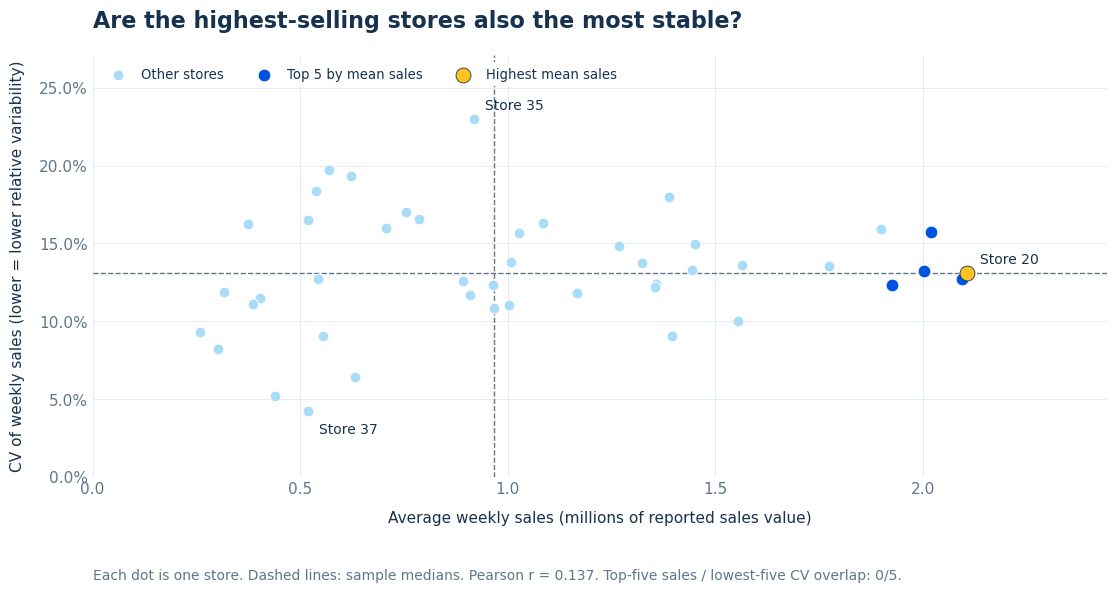

In [60]:
# Use medians across stores as descriptive reference points, not performance targets.
c_mean_cut = c_store_summary["Mean_Sales"].median()
c_cv_cut = c_store_summary["CV"].median()
# Ties at a median are included in the higher group, as in the original analysis.
c_store_summary["Sales_Group"] = np.where(
    c_store_summary["Mean_Sales"] >= c_mean_cut, "Higher sales", "Lower sales"
)
c_store_summary["Volatility_Group"] = np.where(
    c_store_summary["CV"] >= c_cv_cut, "Higher CV", "Lower CV"
)
# Compare relative variability with absolute variability using all 45 stores.
c_pearson = c_store_summary["Mean_Sales"].corr(c_store_summary["CV"])
c_abs_corr = c_store_summary["Mean_Sales"].corr(c_store_summary["SD_Sales"])
c_quadrants = pd.crosstab(c_store_summary["Sales_Group"],
                         c_store_summary["Volatility_Group"])

# Select five stores by each measure; store ID is a deterministic tie-breaker.
c_sales_leaders = c_store_summary.head(5).index
c_cv_order = c_store_summary.sort_values(["CV", "Store_Number"])
c_stability_leaders = c_cv_order.head(5).index
c_overlap = sorted(set(c_sales_leaders).intersection(c_stability_leaders))
print(f"Median of store means: {c_mean_cut / 1_000_000:.3f} million")
print(f"Median store CV: {c_cv_cut:.2%}")
print(f"Mean sales versus CV, Pearson r = {c_pearson:.3f}")
print(f"Mean sales versus absolute SD, Pearson r = {c_abs_corr:.3f}")
print(f"Overlap between top-five sales and lowest-five CV: {len(c_overlap)} of 5 stores")
print("Lowest-CV stores:", ", ".join(f"Store {int(s)}" for s in c_stability_leaders))

# Show where the sales leaders rank on relative stability.
c_leader_comparison = c_store_summary.loc[c_sales_leaders,
    ["Mean_Rank", "Mean_Sales", "CV", "CV_Rank"]].copy()
c_leader_comparison["Mean_Sales"] = c_leader_comparison["Mean_Sales"].round(2)
c_leader_comparison["CV"] = c_leader_comparison["CV"].map(lambda value: f"{value:.2%}")
display(c_leader_comparison)
display(c_quadrants)

# Plot the full sample before highlighting the same sales leaders used in Figure C1.
fig, ax = plt.subplots(figsize=(11.8, 6.2))
c_other_stores = c_store_summary.loc[~c_store_summary.index.isin(c_sales_leaders)]
ax.scatter(c_other_stores["Mean_Sales"] / 1_000_000, c_other_stores["CV"],
           s=60, color=PALE_BLUE, edgecolor="white", linewidth=0.7,
           label="Other stores", zorder=3)
c_top_stores = c_store_summary.loc[c_sales_leaders]
ax.scatter(c_top_stores["Mean_Sales"] / 1_000_000, c_top_stores["CV"],
           s=85, color=BLUE, edgecolor="white", linewidth=0.7,
           label="Top 5 by mean sales", zorder=4)
# Emphasise the highest-selling store without omitting the other stores.
c_best_sales_id = c_sales_leaders[0]
c_best_sales = c_store_summary.loc[c_best_sales_id]
ax.scatter(c_best_sales.Mean_Sales / 1_000_000, c_best_sales.CV,
           s=115, color=YELLOW, edgecolor=INK, linewidth=0.6,
           label="Highest mean sales", zorder=5)
ax.axvline(c_mean_cut / 1_000_000, color=GREY, linestyle="--", linewidth=1)
ax.axhline(c_cv_cut, color=GREY, linestyle="--", linewidth=1)

# Identify the highest-selling store and both extremes of relative variability.
c_low_cv_id = c_cv_order.index[0]
c_high_cv_id = c_cv_order.index[-1]
c_label_offsets = {c_best_sales_id: (9, 7), c_low_cv_id: (8, -16),
                   c_high_cv_id: (8, 7)}
for store, offset in c_label_offsets.items():
    row = c_store_summary.loc[store]
    ax.annotate(f"Store {int(store)}", (row.Mean_Sales / 1_000_000, row.CV),
                xytext=offset, textcoords="offset points", fontsize=10, color=INK)
ax.set_xlabel("Average weekly sales (millions of reported sales value)", labelpad=10)
ax.set_ylabel("CV of weekly sales (lower = lower relative variability)", labelpad=10)
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.set_xlim(0, c_store_summary.Mean_Sales.max() / 1_000_000 * 1.16)
ax.set_ylim(0, c_store_summary.CV.max() * 1.18)
ax.grid(color="#E3EBF3", linewidth=0.7)
ax.set_axisbelow(True)
ax.tick_params(length=0)
ax.set_title("Are the highest-selling stores also the most stable?", loc="left", pad=20)
ax.legend(frameon=True, facecolor="white", edgecolor="none", framealpha=1,
          loc="upper left", ncol=3, fontsize=9.5)
fig.text(0.10, 0.025,
         f"Each dot is one store. Dashed lines: sample medians. Pearson r = {c_pearson:.3f}. "
         f"Top-five sales / lowest-five CV overlap: {len(c_overlap)}/5.",
         fontsize=10, color=GREY)
fig.subplots_adjust(left=0.10, right=0.96, top=0.87, bottom=0.19)
if EXPORT_RESULTS:
    fig.savefig(OUTPUT_DIR / "C2_sales_vs_cv.png", dpi=220, bbox_inches="tight")
plt.show()

#### Key Findings — Sales and Relative Variability

- **No overlap among the leading groups:** none of the five highest-selling stores is among the five with the lowest CV.
- **Store 20 illustrates the distinction:** it ranks first in mean weekly sales but **23rd in CV**, where rank 1 denotes the lowest relative variability.
- **Weak mean–CV association:** the full-sample Pearson correlation is **0.137**.
- **Stronger mean–SD association:** the correlation between mean sales and absolute SD is **0.928**.
- **CV extremes:** Store 37 has the lowest CV (**4.21%**), while Store 35 has the highest (**22.97%**).

**Interpretation.** Sales leadership and low relative variability are different attributes. The weak mean–CV relationship supports evaluating them separately rather than inferring stability from sales rank. The much stronger association with absolute SD also shows why dispersion in sales units should be distinguished from dispersion relative to a store's mean.

**Limitation.** Overlap depends on the five-store cutoff, and Pearson correlation does not capture every form of association. CV includes seasonal as well as other weekly movements; it is not a measure of forecast error.

**Key takeaway:** high sales do not automatically coincide with leading relative stability in this sample.


### C.5 Selected Sales Distributions

Boxplots supplement the rankings and scatterplot by showing all weekly sales observations for nine selected stores: the top three, middle three and bottom three by mean sales. These groups are chosen to illustrate different sales levels and are not a random subsample.

Boxes show the median and interquartile range. Whiskers extend to the most extreme observations within 1.5 IQR of the box boundaries. Values beyond the whiskers are shown separately and remain included in all numerical calculations. The common vertical scale measures sales in millions.


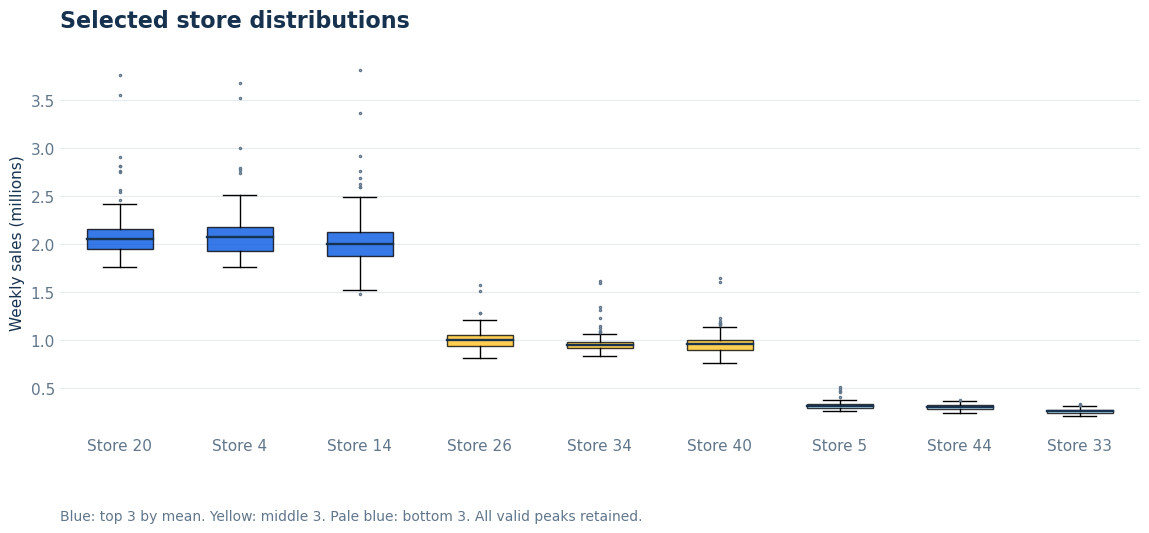

In [63]:
# Select three stores from each of the top, middle and bottom mean-sales ranks.
c_order = c_store_summary.index.tolist()
# Choose three adjacent ranks around the centre of the full store ordering.
c_middle = len(c_order) // 2
c_selected = c_order[:3] + c_order[c_middle-1:c_middle+2] + c_order[-3:]
# Use all weekly observations for each selected store.
c_boxes = [c_data.loc[c_data.Store_Number.eq(s), "Weekly_Sales"].to_numpy() / 1_000_000
           for s in c_selected]
fig, ax = plt.subplots(figsize=(12, 5.6))
# Retain observations outside the 1.5-IQR whiskers in all calculations.
bp = ax.boxplot(c_boxes, patch_artist=True, widths=0.55,
                medianprops={"color": INK, "linewidth": 1.7},
                flierprops={"marker": ".", "markersize": 3, "markeredgecolor": GREY})
# Distinguish rank groups consistently rather than assigning a unique colour to every store.
for patch, colour in zip(bp["boxes"], [BLUE]*3 + [YELLOW]*3 + [PALE_BLUE]*3):
    patch.set_facecolor(colour)
    patch.set_alpha(0.78)
ax.set_xticks(range(1, 10), [f"Store {s}" for s in c_selected])
# The vertical scale measures absolute sales; relative dispersion is assessed separately using CV.
ax.set_ylabel("Weekly sales (millions)")
ax.set_title("Selected store distributions", loc="left", pad=18)
ax.yaxis.grid(True, color="#E3EBF3", linewidth=0.7)
ax.set_axisbelow(True)
ax.tick_params(length=0)
fig.text(0.08, 0.025, "Blue: top 3 by mean. Yellow: middle 3. Pale blue: bottom 3. All valid peaks retained.",
         fontsize=10, color=GREY)
fig.subplots_adjust(left=0.08, right=0.98, top=0.86, bottom=0.18)
if EXPORT_RESULTS:
    fig.savefig(OUTPUT_DIR / "C3_selected_store_boxplots.png", dpi=220, bbox_inches="tight")
plt.show()


#### Key Findings — Distributional Context

- The selected stores occupy different sales levels, providing distributional context for the mean-based ranking.
- Upper-tail peaks in the selected high-selling stores reinforce the value of reporting medians alongside means.
- Box heights and whisker lengths describe **absolute** sales dispersion; they do not directly rank relative stability.

**Interpretation.** Rankings summarise typical levels, while the boxplots show that a mean alone does not describe the full range of weekly outcomes. CV remains necessary for the specific scale-adjusted comparison used in this module.

**Limitation.** The nine stores are selected by sales rank. Their distributions cannot establish that the same features hold uniformly across every store, and observations beyond the whiskers are not established recording errors.

**Key takeaway:** distributional evidence complements store averages without replacing the distinction between sales level and relative variation.


### C.6 Supporting Within-Store Holiday Comparison

For each store, mean sales and observation counts are calculated separately for holiday-labelled and other weeks. The percentage difference is measured relative to the other-week mean. Both comparison groups and positive denominators are checked before calculation.

The full paired results are retained in the exported store summary. This provides a consistency check with Module D while leaving the event-type interpretation and main holiday figures to that module.


In [66]:
# Compare flagged and ordinary weeks within the same store.
c_holiday_means = c_data.groupby(["Store_Number", "Holiday_Flag"])["Weekly_Sales"].mean().unstack()
# Report sample sizes because holiday and ordinary weeks have unequal coverage.
c_holiday_counts = c_data.groupby(["Store_Number", "Holiday_Flag"]).size().unstack(fill_value=0)
# Require both comparison groups before calculating an uplift.
if not {0, 1}.issubset(c_holiday_means.columns):
    raise ValueError("Both holiday and ordinary weeks are needed for uplift.")
if c_holiday_means[[0, 1]].isna().any().any() or c_holiday_means[0].le(0).any():
    raise ValueError("Check missing holiday groups or non-positive ordinary-week means.")
# Align group means and counts by store ID when joining them to the KPI table.
c_store_summary["Ordinary_Mean"] = c_holiday_means[0]
c_store_summary["Holiday_Mean"] = c_holiday_means[1]
c_store_summary["Ordinary_Weeks"] = c_holiday_counts[0]
c_store_summary["Holiday_Weeks"] = c_holiday_counts[1]
# Express the relative difference as a percentage (10 means 10%).
c_store_summary["Holiday_Uplift_Pct"] = (
    c_store_summary.Holiday_Mean / c_store_summary.Ordinary_Mean - 1
) * 100
# Keep the full paired results in the CSV; avoid repeating Module D's main table.
c_positive_uplift = int(c_store_summary["Holiday_Uplift_Pct"].gt(0).sum())
print(f"Supporting comparison: {c_positive_uplift} of {c_n_stores} stores have positive observed uplift.")
print("Paired means, group counts and uplift are included in C_store_summary.csv.")
# Export one consolidated store-level table, including supporting holiday metrics.
if EXPORT_RESULTS:
    # Retain the store identifier as a named column in the exported summary.
    c_store_summary.to_csv(OUTPUT_DIR / "C_store_summary.csv", index_label="Store_Number")

Supporting comparison: 40 of 45 stores have positive observed uplift.
Paired means, group counts and uplift are included in C_store_summary.csv.


#### Supporting Finding and Handover

Holiday-labelled weeks have higher mean sales in **40 of 45 stores**. The finding is consistent with Module D's separate within-store comparison and indicates that the positive pattern is not confined to a single store.

The full paired means, counts and percentage differences are retained in `C_store_summary.csv`. Module D reports the detailed interpretation and exceptions.

**Key takeaway:** the positive holiday-labelled association is widespread across stores, with its interpretation examined more fully in Module D.


### C.7 Module Conclusions and Limitations

#### Main Findings

1. **Substantial sales-level differences:** the highest and lowest store means differ by a factor of 8.11.
2. **Broadly consistent sales rankings:** mean- and median-based rankings are closely aligned.
3. **Distinct relative-stability rankings:** the top-five sales group and lowest-five CV group have no overlap, and the full-sample mean–CV correlation is weak.
4. **Complementary distributional evidence:** selected boxplots show why averages, absolute dispersion and relative variability answer different questions.

#### Interpretation and Limitations

Store sales should be evaluated along separate dimensions of typical level and relative variation. The specific analytical choices are the top-five cutoff, the sample-median reference lines and CV as a measure of relative dispersion. These choices organise the comparisons rather than define universal performance standards.

The study-wide limitations address missing store characteristics, the historical observation period and the boundaries on explanations of store performance.

Module D next combines the holiday comparison with the time-pattern evidence from Module B to assess what the provider's holiday indicator captures.

**Key takeaway:** sales leadership and relative stability should be assessed separately within the limits of the observed panel.


## Module D: Holiday-Labelled Weeks and Seasonal Peaks

**Research question:** How do sales differ between holiday-labelled and other weeks, and does the original holiday indicator capture the largest seasonal peaks?

This module combines three comparisons: pooled group averages, within-store percentage differences and averages for four inferred event types. It then checks the two highest-selling December dates identified in Module B against the original binary flag.

The term *uplift* in the code denotes an observed percentage difference in mean sales. It is not a controlled estimate of the effect of holidays. The provider's original labels are preserved throughout.


### D.1 Local Data View and Traceability

A separate working copy of `raw_df` retains the numeric store identifiers and original date strings used by this module. The source CSV is not read again. The numeric sales series is drawn from Module A's cleaned data in the next step.

This local representation supports the existing date-string comparisons without altering the protected source or the shared cleaned dataset.


In [71]:
# Create a separate view without reading the original CSV again.
# Original numeric store IDs and date strings are retained for the comparisons below.
# The protected raw_df and shared clean_df remain available independently.
df = raw_df.copy()
print(df.shape)
print(df.columns)
df.head()


(6435, 8)
Index(['Store_Number', 'Date', 'Weekly_Sales', 'Holiday_Flag', 'Temperature',
       'Fuel_Price', ' CPI ', 'Unemployment'],
      dtype='object')


,Store_Number,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,2/5/2010,"1,643,691",0,42.31,2.572,211,8.106
1,1,2/12/2010,"1,641,957",1,38.51,2.548,211,8.106
2,1,2/19/2010,"1,611,968",0,39.93,2.514,211,8.106
3,1,2/26/2010,"1,409,728",0,46.63,2.561,211,8.106
4,1,3/5/2010,"1,554,807",0,46.50,2.625,211,8.106


### D.2 Numeric Sales and Validation

The cleaned numeric sales values are assigned to the local `Sales` field by the unchanged source-row index. Additional comma removal or sales conversion is therefore unnecessary.

The inspection confirms row counts, missing sales, store and date coverage, duplicate keys and the observed sales range. All observations and original holiday flags are retained. These checks maintain consistency with the common analysis sample.


In [73]:
# Reuse the numeric sales series from Module A instead of repeating the conversion.
# Assignment aligns by the original row index, which cleaning has preserved.
# The local raw-text Weekly_Sales field remains available for traceability.
df["Sales"] = clean_df["Weekly_Sales"]

# Confirm coverage and key integrity without deleting records or redefining the holiday flag.
print("Rows and columns:", df.shape)
print("Missing sales:", df["Sales"].isna().sum())
print("Stores:", df["Store_Number"].nunique())
print("Dates:", df["Date"].nunique())
print("Duplicate store-date rows:", df.duplicated(["Store_Number", "Date"]).sum())
print("Minimum and maximum sales:", df["Sales"].min(), df["Sales"].max())


Rows and columns: (6435, 9)
Missing sales: 0
Stores: 45
Dates: 143
Duplicate store-date rows: 0
Minimum and maximum sales: 209986.0 3818686.0


### D.3 Pooled Holiday and Other-Week Comparison

The sample is divided using the original `Holiday_Flag`. Mean, median, SD and observation counts describe the two groups. The percentage difference is calculated as:

$$\text{Observed difference (\%)} = \frac{\bar{x}_{H}-\bar{x}_{O}}{\bar{x}_{O}}\times 100,$$

where $\bar{x}_{H}$ is mean sales for holiday-labelled observations and $\bar{x}_{O}$ is mean sales for other observations.

**Dispersion convention.** Sample SD (`ddof=1`) is used throughout Modules A, C and D. This gives the descriptive tables a consistent definition of dispersion. The observed mean difference is calculated independently of SD.


In [75]:
# Compare sales using the original binary holiday flag.
# Counts refer to store-week observations, with 45 stores observed on each date.
holiday = df.loc[df["Holiday_Flag"] == 1, "Sales"]
non_holiday = df.loc[df["Holiday_Flag"] == 0, "Sales"]

# Report both location and dispersion because group sizes and sales distributions differ.
# Use sample SD (ddof=1), consistent with the descriptive statistics in Modules A and C.
# The SD convention does not change group means, medians or the observed percentage difference.
comparison = pd.DataFrame({
    "Week type": ["Non-holiday", "Holiday"],
    "Count": [len(non_holiday), len(holiday)],
    "Mean": [np.mean(non_holiday), np.mean(holiday)],
    "Median": [np.median(non_holiday), np.median(holiday)],
    "Std": [np.std(non_holiday, ddof=1), np.std(holiday, ddof=1)]
})
print(comparison)

# Express the observed mean difference relative to the non-holiday-labelled mean.
# The variable name uplift denotes a descriptive percentage difference, not a causal effect.
uplift = (np.mean(holiday) - np.mean(non_holiday)) / np.mean(non_holiday) * 100
print("Holiday uplift (%):", round(uplift, 2))


     Week type  Count          Mean     Median            Std
0  Non-holiday   5985  1.041256e+06   956211.0  558957.434617
1      Holiday    450  1.122888e+06  1018538.0  627684.934637
Holiday uplift (%): 7.84


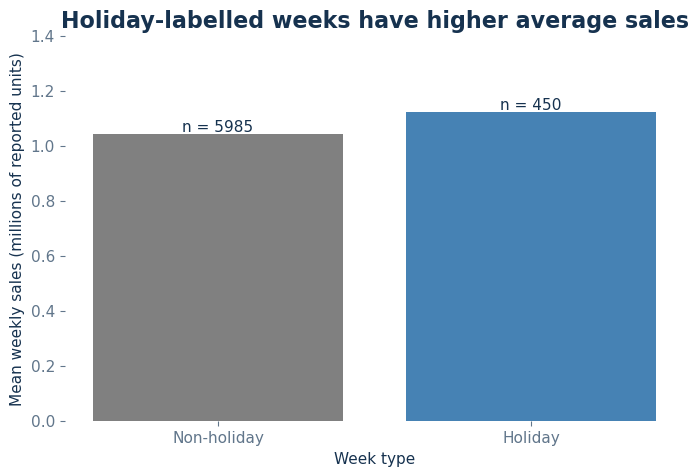

In [76]:
# Compare group means on a common scale in millions of reported sales value.
# The source currency is unverified, so the axis does not assume a currency symbol.
plt.figure(figsize=(8, 5))
plt.bar(
    ["Non-holiday", "Holiday"],
    [np.mean(non_holiday) / 1000000, np.mean(holiday) / 1000000],
    color=["gray", "steelblue"]
)
plt.title("Holiday-labelled weeks have higher average sales")
plt.xlabel("Week type")
plt.ylabel("Mean weekly sales (millions of reported units)")
# Display store-week counts above the bars to make unequal group sizes explicit.
plt.text(0, np.mean(non_holiday) / 1000000, "n = " + str(len(non_holiday)), ha="center", va="bottom")
plt.text(1, np.mean(holiday) / 1000000, "n = " + str(len(holiday)), ha="center", va="bottom")
plt.ylim(0, 1.4)
plt.show()


#### Key Findings — Pooled Holiday Comparison

- **Holiday-labelled mean:** approximately **1.123 million**, based on **450 store-week observations**.
- **Other-week mean:** approximately **1.041 million**, based on **5,985 observations**.
- **Observed mean difference:** **7.84%**, relative to the other-week mean.
- **Median comparison:** approximately **1.019 million** for holiday-labelled observations versus **0.956 million** for other observations.

**Interpretation.** Both mean and median sales are higher in the holiday-labelled group. The positive pattern is therefore visible in more than one measure of central location. However, the comparison pools stores and selected dates; it does not isolate the contribution of the holiday label from calendar timing or other conditions.

**Limitation.** The 450 labelled observations represent only ten distinct dates. The group comparison has much less event-level coverage than its row count alone suggests.

**Key takeaway:** holiday-labelled observations have higher average sales, with the percentage difference interpreted descriptively.


### D.4 Within-Store Comparisons

The pooled comparison is repeated separately for each of the 45 stores. Each percentage difference uses that store's other-week mean as its denominator. Positive values indicate higher observed average sales in its holiday-labelled weeks.

This comparison checks whether the pooled pattern is widespread rather than concentrated in a small number of stores. It holds store identity fixed but does not remove differences in calendar timing, promotions or other time-varying conditions.


In [79]:
# Repeat the comparison within each store to check how widespread the pooled pattern is.
# Holding store identity fixed does not control for seasonal timing or promotions.
store_numbers = []
store_uplifts = []
# Use the numeric store identifiers retained in the local data view.
for store in range(1, 46):
    store_data = df.loc[df["Store_Number"] == store]
    store_holiday = store_data.loc[store_data["Holiday_Flag"] == 1, "Sales"]
    store_other = store_data.loc[store_data["Holiday_Flag"] == 0, "Sales"]
    store_uplift = (np.mean(store_holiday) - np.mean(store_other)) / np.mean(store_other) * 100
    store_numbers.append(store)
    store_uplifts.append(store_uplift)
# Retain every store, including those with zero or negative observed differences.
store_comparison = pd.DataFrame({"Store": store_numbers, "Uplift (%)": store_uplifts})
print(store_comparison)
print("Stores with positive uplift:", len(store_comparison.loc[store_comparison["Uplift (%)"] > 0]))


    Store  Uplift (%)
0       1    7.678956
1       2    8.622795
2       3    9.435006
3       4    7.657427
4       5   14.166544
5       6    8.027996
6       7   19.439218
7       8    7.921190
8       9    8.944049
9      10   12.236251
10     11    7.331011
11     12   13.894689
12     13    5.896122
13     14    5.318810
14     15   14.478400
15     16    9.900827
16     17   10.449557
17     18    8.445543
18     19    9.893327
19     20    7.247646
20     21   10.085208
21     22    5.917636
22     23    5.644488
23     24    9.440238
24     25    5.031366
25     26    7.450334
26     27    7.126670
27     28   12.680621
28     29   13.582604
29     30   -0.421623
30     31    8.065401
31     32    3.438317
32     33    1.131643
33     34    8.412045
34     35   18.307388
35     36   -1.688113
36     37   -2.353118
37     38   -1.175801
38     39    7.484682
39     40    4.913185
40     41    5.688112
41     42    2.185048
42     43    0.445175
43     44   -2.380179
44     45 

#### Key Findings — Within-Store Pattern

- **Positive differences:** **40 of 45 stores** have higher mean sales in their holiday-labelled weeks.
- **Exceptions:** Stores **30, 36, 37, 38 and 44** have negative observed percentage differences.
- **Consistency across modules:** the count of 40 positive stores matches Module C's supporting store-level summary.

**Interpretation.** The pooled association is widespread but not universal. Reporting the exceptions prevents an overall average from implying that every store follows the same pattern.

**Limitation.** Comparing each store with itself retains differences in calendar timing and other time-varying conditions. It is therefore not a controlled holiday comparison.

**Key takeaway:** most stores show a positive observed difference, while store-level variation remains relevant.


### D.5 Comparison of Inferred Holiday Types

`Holiday_Flag` contains no event names. The ten marked dates are assigned to four commonly associated event types following the project mapping: Super Bowl, Labor Day, Thanksgiving and Christmas-related. These names are **inferred labels**, not additional source fields.

The **Christmas-related** category uses the same name as Module A and refers specifically to December 30/31. These dates are distinct from the pre-Christmas peaks, which is essential when interpreting the event comparison. The competition data page provides the calendar context for the mapping [2].

Counts differ across categories: Super Bowl and Labor Day each include three dates, or 135 store-week observations; Thanksgiving and Christmas-related each include two dates, or 90 observations. The sample ends before the November–December 2012 period.


In [82]:
# Infer event names from the ten dates marked by the original provider flag.
# These categories are constructed labels, not additional source information.
# Use the same Christmas-related label as Module A for the December 30/31 dates.
holiday_dates = {
    "Super Bowl": ["2/12/2010", "2/11/2011", "2/10/2012"],
    "Labor Day": ["9/10/2010", "9/9/2011", "9/7/2012"],
    "Thanksgiving": ["11/26/2010", "11/25/2011"],
    "Christmas-related": ["12/31/2010", "12/30/2011"]
}

print("Marked holiday dates:", df.loc[df["Holiday_Flag"] == 1, "Date"].unique())

type_names = []
type_counts = []
type_means = []
type_medians = []

# Require both a matching source date string and Holiday_Flag = 1.
# Each matched date contributes 45 observations; event counts differ across the partial years.
for name in holiday_dates:
    event_sales = []
    for date in holiday_dates[name]:
        selected = df.loc[
            (df["Date"] == date) & (df["Holiday_Flag"] == 1),
            "Sales"
        ]
        for value in selected:
            event_sales.append(value)

    type_names.append(name)
    type_counts.append(len(event_sales))
    type_means.append(np.mean(event_sales))
    type_medians.append(np.median(event_sales))

# Report counts alongside means and medians to document the support for each event category.
type_comparison = pd.DataFrame({
    "Holiday type (inferred)": type_names,
    "Count": type_counts,
    "Mean sales": type_means,
    "Median sales": type_medians
})
print(type_comparison)
# The category counts should cover all 450 holiday-labelled store-week observations.
print("Total mapped records:", sum(type_counts))


Marked holiday dates: ['2/12/2010' '9/10/2010' '11/26/2010' '12/31/2010' '2/11/2011' '9/9/2011'
 '11/25/2011' '12/30/2011' '2/10/2012' '9/7/2012']
  Holiday type (inferred)  Count    Mean sales  Median sales
0              Super Bowl    135  1.079128e+06     1015655.0
1               Labor Day    135  1.042427e+06      976416.0
2            Thanksgiving     90  1.471273e+06     1327536.5
3       Christmas-related     90  9.608331e+05      889822.0
Total mapped records: 450


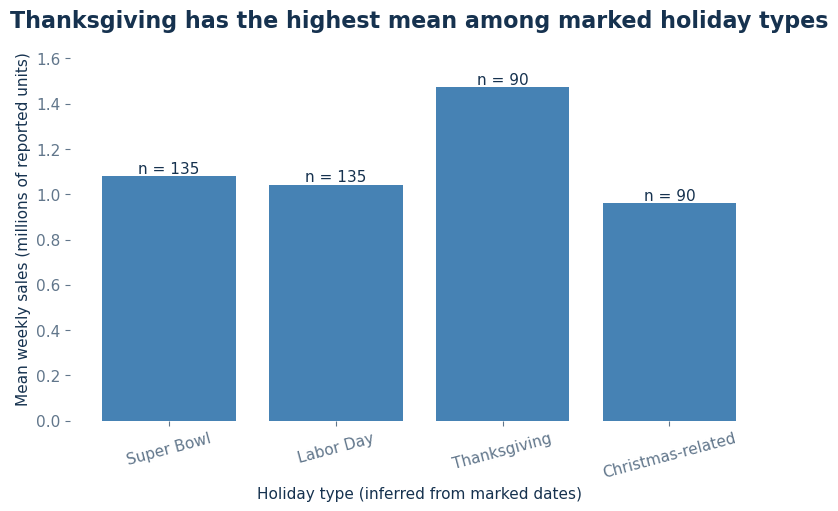

In [83]:
# Plot observed event-group means in millions without implying a controlled event comparison.
# Category names are inferred and group counts differ.
plt.figure(figsize=(9, 5))
plt.bar(type_names, np.array(type_means) / 1000000, color="steelblue")
plt.title("Thanksgiving has the highest mean among marked holiday types")
plt.xlabel("Holiday type (inferred from marked dates)")
plt.ylabel("Mean weekly sales (millions of reported units)")
plt.xticks(rotation=15)
# Show the number of store-week observations supporting each event average.
for i in range(len(type_names)):
    plt.text(i, type_means[i] / 1000000, "n = " + str(type_counts[i]),
             ha="center", va="bottom")
plt.ylim(0, 1.7)
# Display the chart with the existing vertical range.
plt.show()


#### Key Findings — Inferred Event Types

Mean weekly sales per store-week differ across the four inferred categories:

- **Thanksgiving:** approximately **1.471 million**, based on 90 observations.
- **Super Bowl:** approximately **1.079 million**, based on 135 observations.
- **Labor Day:** approximately **1.042 million**, based on 135 observations.
- **Christmas-related:** approximately **0.961 million**, based on 90 observations.

**Interpretation.** Thanksgiving has the highest observed mean among the flagged categories. The comparatively low Christmas-related mean also highlights the importance of date definitions: the category refers to December 30/31, rather than the pre-Christmas peaks visible in Module B.

**Limitation.** Each category contains only two or three distinct dates, so its average is sensitive to the selected calendar observations.

**Key takeaway:** the four labelled categories have different observed sales levels, but their meanings depend on the exact dates included.


### D.6 Unflagged Late-December Sales Peaks

Module B identifies 24 December 2010 and 23 December 2011 as the two highest-selling dates after averaging across stores. The checks below inspect their original holiday flags and store counts.

The objective is to assess indicator coverage, rather than to relabel observations after seeing their sales values. A seasonal shopping peak and a provider-defined holiday-labelled week need not refer to the same date.


In [86]:
# Check the two highest-selling dates identified by the weekly series in Module B.
# Retain the original flag even when a large shopping peak is not holiday-labelled.
# These dates demonstrate the indicator's incomplete coverage of seasonal sales peaks.
peak_dates = ["12/24/2010", "12/23/2011"]
for date in peak_dates:
    subset = df.loc[df["Date"] == date]
    print(date, "mean:", np.mean(subset["Sales"]), "holiday flag:", subset["Holiday_Flag"].iloc[0], "stores:", len(subset))


12/24/2010 mean: 1798475.8666666667 holiday flag: 0 stores: 45
12/23/2011 mean: 1711072.0 holiday flag: 0 stores: 45


#### Key Findings — Indicator Coverage

- **24 December 2010:** mean sales are approximately **1.80 million** across 45 stores; the original holiday flag is **0**.
- **23 December 2011:** mean sales are approximately **1.71 million** across 45 stores; the original holiday flag is also **0**.

**Interpretation.** These are the two highest weekly sample averages, yet neither is holiday-labelled. The result reconciles Module B's strong December peaks with the lower Christmas-related category mean: they refer to different reported weeks.

**Limitation.** This check demonstrates incomplete coverage of observed seasonal peaks. It does not show that the provider's flag is erroneous, because its intended definition may be narrower than all holiday-related shopping activity.

**Key takeaway:** `Holiday_Flag` should not be treated as a complete indicator of seasonal demand peaks.


### D.7 Module Conclusions and Limitations

#### Main Findings

1. **Positive pooled association:** holiday-labelled weeks have 7.84% higher mean sales than other weeks.
2. **Widespread but non-uniform store pattern:** 40 of 45 stores have a positive within-store percentage difference.
3. **Variation across inferred event types:** Thanksgiving has the highest observed mean among the four categories.
4. **Incomplete coverage of seasonal peaks:** both highest-selling December dates have `Holiday_Flag = 0`.

#### Interpretation and Limitations

The binary indicator provides useful context, but it is not a comprehensive measure of seasonal shopping activity. The lower mean for the Christmas-related category should not be interpreted as evidence that pre-Christmas shopping is weak: its marked dates occur after the two observed pre-Christmas peaks.

The principal constraint is event coverage: the flag identifies only ten dates, with two or three dates per inferred category. The broader implications of shared weeks, unobserved influences and descriptive methods are consolidated below.

**Key takeaway:** holiday-labelled weeks tend to have higher observed sales, while the largest seasonal peaks require information beyond the original binary label.


## Overall Conclusions

The four modules provide complementary evidence about the same validated historical panel. Data completeness supports comparisons, while the visual results show why a single sales average or binary indicator cannot describe the full pattern.

### Answers to the Research Questions

| Research question | Main evidence | Conclusion within the sample |
|---|---|---|
| Are seasonal peaks more prominent than year-to-year changes? | Weekly peaks of approximately 1.80 million and 1.71 million; strongest monthly averages in December and November; February–October yearly averages of approximately 1.018–1.043 million | Recurring year-end peaks are more prominent than the differences between the comparable-period yearly averages. |
| How do sales levels relate to relative stability? | An 8.11-fold highest-to-lowest store mean ratio; no overlap between the top-five sales and lowest-five CV groups; mean–CV correlation of 0.137 | Store sales levels differ greatly, while sales leadership and low relative variability warrant separate assessment. |
| What does the holiday label capture? | A 7.84% pooled mean difference; positive differences in 40 of 45 stores; both largest December peaks have flag 0 | Holiday-labelled weeks tend to have higher observed sales, but the indicator does not cover all seasonal shopping peaks. |

### Integrated Interpretation

**Aggregation matters.** The pooled mean is approximately 9.0% above the pooled median, and store means span a wide range. Aggregate averages therefore benefit from distributional and store-level context. A measure of central location is useful, but it is not a complete description of performance.

**Sales level and variability answer different questions.** A store can generate high typical sales without having the lowest relative fluctuations. Absolute SD and CV also describe different dimensions: one is measured in sales units, while the other is scaled by mean sales.

**Labels require validation against their dates.** The association with holiday-labelled weeks and the existence of unflagged December peaks are compatible findings. The indicator captures selected provider-defined weeks, whereas the time series reveals a broader seasonal pattern. Definitions must therefore be examined before attaching an economic explanation to a category.

**Implications for further assessment.** Within the observed sample, peak weeks merit separate attention from annual averages, stores merit comparison on both sales level and relative variation, and holiday labels merit comparison with the actual calendar pattern. These are analytical implications rather than established prescriptions about staffing, inventory or profitability.


## Study-Wide Limitations

The conclusions should be read within the following boundaries:

1. **Source and measurement verification.** The supplied CSV is internally consistent, but its exact lineage, original precision and several measurement units are not independently established. Reported sales values are not assumed to be verified currency amounts.
2. **Historical scope and generalisability.** The sample covers 45 anonymous stores over February 2010–October 2012. It does not represent three complete years or establish current Walmart-wide conditions.
3. **Unobserved store and time-varying characteristics.** Store size, location, type, footfall, pricing, promotions, costs and profits are unavailable. Consequently, the analysis cannot explain all sales differences or infer profitability and management quality.
4. **Calendar coverage and event support.** Monthly and annual comparisons use different available dates. Holiday categories contain only two or three flagged dates each, limiting claims about persistent event-specific patterns.
5. **Dependence across observations.** Weekly records repeat the same stores, while stores share calendar dates and potentially common influences. The number of rows is not the number of independent events.
6. **Descriptive methods and selected summaries.** Moving averages, correlations, top-five comparisons and selected boxplots organise the evidence but do not establish statistical significance, causal effects or forecasting performance. Median divisions and ranking cutoffs are analytical choices.

These limitations do not invalidate the observed comparisons. They define the scope of the conclusions and the additional evidence required to move from description to explanation or prediction.


## Directions for Further Analysis

Further work could extend the study in four connected directions:

- **Verify and extend the source.** Document file lineage, confirm measurement units and collect a longer panel with complete calendar years. More annual cycles would support stronger assessment of recurring seasonality.
- **Enrich store and calendar information.** Add verified store characteristics, promotion and pricing data, and a documented calendar of event and shopping weeks. New calendar indicators should be distinguished from the original provider flag.
- **Assess robustness of the descriptive comparisons.** Examine whether the findings persist across alternative common-period definitions, ranking cutoffs and measures of typical sales or variability. This would assess sensitivity to the current analytical choices.
- **Develop explanatory or predictive models only with appropriate validation.** A panel analysis could account for store and calendar differences, with uncertainty estimates reflecting repeated stores and shared weeks. Forecasting work would require time-ordered validation and comparison against suitable baselines. Neither extension would automatically establish causality.

**Final conclusion:** the panel reveals pronounced seasonal peaks, substantial differences in store sales levels and a distinction between sales leadership and relative stability. Holiday labels add useful context but capture only part of the seasonal pattern. A complete interpretation therefore combines validated data, complementary visual summaries and explicit limits on what the evidence can establish.


## References and Data Provenance

[1] *Walmart Dataset* (n.d.). Kaggle, dataset page under the account `yasserh`. Available at: https://www.kaggle.com/datasets/yasserh/walmart-dataset (page reviewed 30 October 2026).

**Use in this study:** associated public dataset page for the group-supplied `Walmart_sales_analysis.csv`. Every calculation in this notebook uses the supplied CSV, not a newly downloaded replacement.

[2] Kaggle (n.d.). *Walmart Recruiting – Store Sales Forecasting: Data*. Available at: https://www.kaggle.com/c/walmart-recruiting-store-sales-forecasting/data (page reviewed 30 October 2026).

**Use in this study:** competition context referenced for the holiday-week mapping. Event names are inferred and checked against the ten marked dates in the supplied file; the original `Holiday_Flag` remains unchanged. The term **Christmas-related** distinguishes the December 30/31 category from the unflagged pre-Christmas sales peaks.

[3] Rabetti, D. (n.d.). *Project Guidelines*. BMT5101, National University of Singapore. Instructor-provided course material (`！Project_Guidelines_2027.pdf`).

**Use in this study:** the exploratory-analysis framework, documentation requirements and suggested grading criteria.

**Provenance boundary:** the public links identify the associated dataset and competition context; they do not independently establish exact equivalence between the supplied CSV and any remotely hosted version. File lineage, measurement units and absent original precision therefore retain the qualifications stated in A.1–A.3. All reported results are calculated from the validated local file.
